# 🤖 NewsBot Intelligence System
## ITAI 2373 Mid-Term Project

**Author:** Kristina Akpan (individual submission)
**Date:** October 2026
**GitHub Repository:** https://github.com/bookwithkai2/ITAI2373-NewsBot-Midterm

---

## 🎯 Project Overview

NewsBot is an end to end NLP system that turns raw news articles into structured intelligence. Given an article, it:

* 📰 **Processes** the text with a robust cleaning and normalization pipeline
* 🏷️ **Classifies** the article into a news category (Business, Entertainment, Politics, Sports, Technology)
* 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
* 😊 **Analyzes** sentiment and emotional tone
* 🌳 **Parses** sentence structure to recover who did what to whom
* 📊 **Generates** insights for media monitoring and business intelligence

**Dataset:** BBC News corpus (Greene and Cunningham, 2006), the source of the Kaggle *Learn AI BBC* competition recommended in the project instructions. We sample 2,000 unique articles across 5 categories.

### 📚 Module Integration Checklist
* [x] **Module 1:** NLP applications and real world context
* [x] **Module 2:** Text preprocessing pipeline
* [x] **Module 3:** TF-IDF feature extraction with parameter optimization
* [x] **Module 4:** POS tagging analysis
* [x] **Module 5:** Syntax parsing and semantic analysis
* [x] **Module 6:** Sentiment and emotion analysis
* [x] **Module 7:** Multi class text classification system
* [x] **Module 8:** Named Entity Recognition and relationship mapping

---

## 📦 Setup and Installation

Run this cell first. Everything here works on the Google Colab free tier (CPU only, no paid resources).

In [1]:
# Install required packages (run this cell first!)
!pip install -q spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly networkx
!python -m spacy download en_core_web_sm -q

# Download NLTK data (punkt_tab and averaged_perceptron_tagger_eng are needed by newer NLTK versions)
import nltk
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4', 'vader_lexicon',
            'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
    nltk.download(pkg, quiet=True)

print("✅ All packages installed successfully!")

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


✅ All packages installed successfully!


In [2]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
import networkx as nx
from collections import Counter, defaultdict
from itertools import combinations
import re
import html
import time
import unicodedata
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
from spacy import displacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     StratifiedKFold, GridSearchCV)
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score, f1_score)
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from scipy.stats import kruskal

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")
CATEGORY_ORDER = ['Business', 'Entertainment', 'Politics', 'Sports', 'Technology']
CAT_COLORS = dict(zip(CATEGORY_ORDER, sns.color_palette('husl', 5)))

print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0


## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

**Business case.** Newsrooms, PR agencies, investment firms and research groups all face the same problem: thousands of articles arrive every day and humans cannot read, tag and summarize them fast enough. NewsBot automates the first pass. It routes each article to the right desk, pulls out the people, companies, places and dollar amounts it mentions, and flags its tone, so that analysts spend their time on judgment rather than sorting.

**Industry context.** The same pipeline powers Google News style aggregation, Bloomberg and Reuters style market monitoring, Meltwater and Cision style media monitoring, and the content tagging systems inside every large publisher's CMS.

**Target users and value proposition.**

| User | Pain point | What NewsBot gives them |
|:---|:---|:---|
| Newsroom editors | Manual tagging and routing of wire copy | Automatic category routing with a confidence score and a review flag |
| PR and communications teams | Tracking every mention of a client or competitor | Entity extraction plus the sentiment of the coverage around each entity |
| Financial analysts | Spotting market moving news early | MONEY, ORG and GPE extraction from business news, with tone |
| Media researchers | Measuring framing and bias at scale | Category level sentiment, emotion and writing style profiles |

**💡 Discussion Question: other real world applications.**
* **Finance:** event driven trading signals (mergers, earnings, lawsuits) and ESG controversy monitoring.
* **Government and policy:** tracking legislative coverage and public reaction to policies.
* **Healthcare:** pharmacovigilance and outbreak monitoring from news and reports.
* **Law and compliance:** adverse media screening of clients for anti money laundering checks.
* **Supply chain:** early warnings about strikes, disasters or sanctions that affect suppliers.
* **Education and libraries:** automatic indexing of archives for search.

**Dataset choice.** We use the BBC News corpus, the dataset recommended in the instructions. The Kaggle competition copy is lowercased and has no headlines, which badly hurts NER and POS tagging (both rely on capitalization). We therefore load the original cased version of the same corpus, which keeps the headline as the first line of each article. If you prefer the Kaggle file, upload BBC News Train.csv and the loader below will use it instead.

In [3]:
# Load the dataset
# Primary source: original cased BBC News corpus (2,225 articles, 5 categories), the same corpus
# behind the Kaggle "learn-ai-bbc" competition, but with headlines and capitalization intact.
DATA_URL = ("https://raw.githubusercontent.com/suraj-deshmukh/"
            "BBC-Dataset-News-Classification/master/dataset/dataset.csv")
KAGGLE_FILE = 'BBC News Train.csv'   # optional fallback if you downloaded it from Kaggle
MAX_ARTICLES = 2000                  # project limit for Colab
CATEGORY_MAP = {'business': 'Business', 'entertainment': 'Entertainment', 'politics': 'Politics',
                'sport': 'Sports', 'tech': 'Technology'}

import os
if os.path.exists(KAGGLE_FILE):
    raw = pd.read_csv(KAGGLE_FILE)
    raw = raw.rename(columns={'Text': 'content', 'Category': 'category'})
    raw['title'] = raw['content'].str.split('.').str[0].str.strip()   # Kaggle copy has no headlines
    print("Loaded Kaggle copy (lowercased, no headlines)")
else:
    raw = pd.read_csv(DATA_URL, encoding='latin-1')
    raw['news'] = raw['news'].str.replace('Â£', '£', regex=False)   # fix a known encoding artifact
    parts = raw['news'].str.strip().str.split('\n', n=1, expand=True)
    raw['title'] = parts[0].str.strip()
    raw['content'] = (parts[1].fillna('')
                      .str.replace(r'\s*\n\s*', ' ', regex=True)       # collapse paragraph breaks
                      .str.strip())
    raw['category'] = raw['type']
    print("Loaded original BBC News corpus")

raw['category'] = raw['category'].str.lower().map(CATEGORY_MAP)
print(f"Raw shape: {raw.shape}")

# Data preparation: drop missing values and duplicates, then a stratified sample of 2,000 articles
df = raw.dropna(subset=['content', 'category'])
df = df[df['content'].str.split().str.len() > 20]           # substantial text only
n_dupes = df.duplicated(subset=['content']).sum()
df = df.drop_duplicates(subset=['content']).reset_index(drop=True)
print(f"Removed {n_dupes} duplicate articles")

if len(df) > MAX_ARTICLES:
    df, _ = train_test_split(df, train_size=MAX_ARTICLES, stratify=df['category'],
                             random_state=RANDOM_STATE)
df = df[['title', 'content', 'category']].reset_index(drop=True)
df.insert(0, 'article_id', range(1, len(df) + 1))
df.to_csv('newsbot_dataset.csv', index=False)

print(f"📊 Dataset loaded successfully!")
print(f"📈 Shape: {df.shape}")
print(f"📋 Columns: {list(df.columns)}")
print("✅ Prepared dataset saved as newsbot_dataset.csv")

# Display first few rows
df.head()

Loaded original BBC News corpus
Raw shape: (2225, 5)
Removed 136 duplicate articles
📊 Dataset loaded successfully!
📈 Shape: (2000, 4)
📋 Columns: ['article_id', 'title', 'content', 'category']
✅ Prepared dataset saved as newsbot_dataset.csv


,article_id,title,content,category
0,1,Lib Dems unveil women's manifesto,The Liberal Democrats are attempting to woo fe...,Politics
1,2,The pirates with no profit motive,Two men who were part of a huge network of int...,Technology
2,3,Pavey focuses on indoor success,Jo Pavey will miss January's View From Great E...,Sports
3,4,Swiss cement firm in buying spree,Swiss cement firm Holcim has bid $800m (£429m)...,Business
4,5,BT offers equal access to rivals,BT has moved to pre-empt a possible break-up o...,Business


📊 DATASET OVERVIEW
Total articles: 2000
Unique categories: 5
Categories: ['Business', 'Entertainment', 'Politics', 'Sports', 'Technology']

📈 CATEGORY DISTRIBUTION
category
Business         479
Sports           471
Politics         377
Entertainment    350
Technology       323
Name: count, dtype: int64
Imbalance ratio (largest / smallest): 1.48

🔎 DATA QUALITY CHECKS
Missing values per column:
article_id    0
title         0
content       0
category      0
Empty titles: 0
Duplicate titles: 26
Non ASCII characters present in: 589 articles (mostly £ signs)



📏 TEXT LENGTH STATISTICS (content words)
              word_count        sentence_count        title_words       
                    mean median           mean median        mean median
category                                                                
Business           325.6  295.0           15.8   14.0         5.4    5.0
Entertainment      330.4  257.5           16.6   13.0         5.4    5.0
Politics           456.1  440.0           21.3   20.0         5.1    5.0
Sports             322.5  285.0           17.0   15.0         4.9    5.0
Technology         512.1  461.0           24.8   21.0         5.3    5.0

Shortest article: 84 words, longest: 4428 words


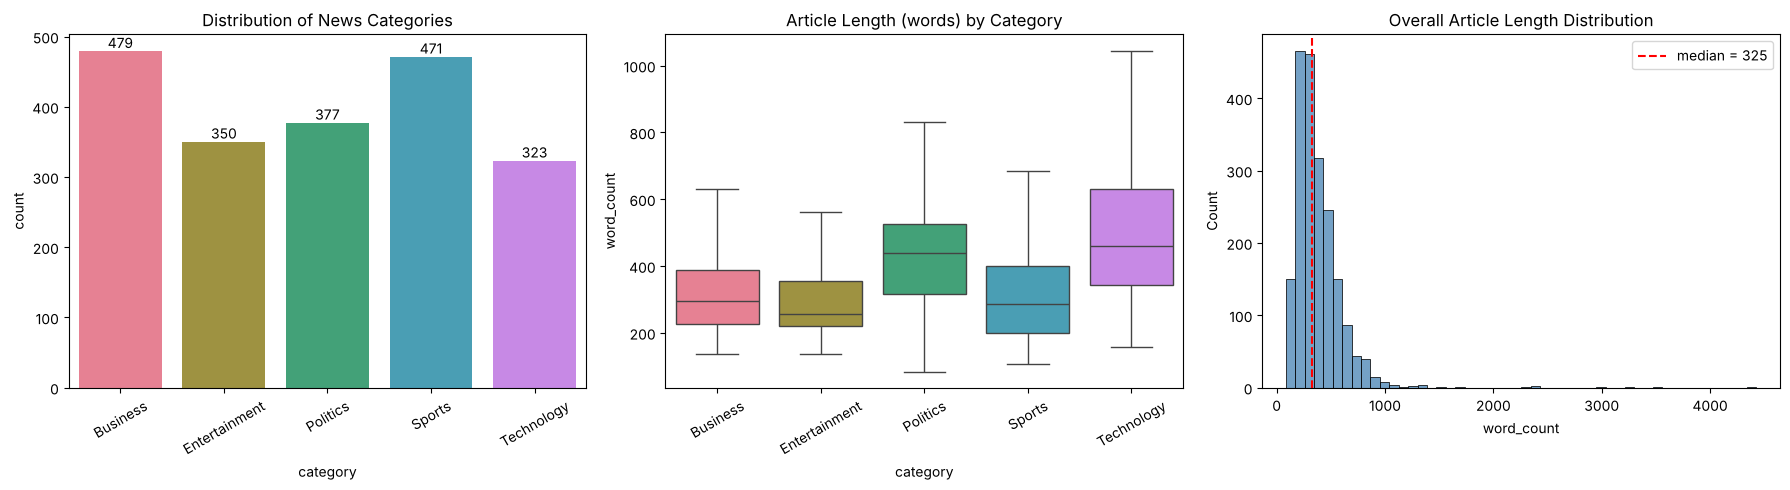

In [4]:
# Basic dataset exploration
print("📊 DATASET OVERVIEW")
print("=" * 50)
print(f"Total articles: {len(df)}")
print(f"Unique categories: {df['category'].nunique()}")
print(f"Categories: {sorted(df['category'].unique().tolist())}")

print("\n📈 CATEGORY DISTRIBUTION")
print("=" * 50)
category_counts = df['category'].value_counts()
print(category_counts)
print(f"Imbalance ratio (largest / smallest): {category_counts.max() / category_counts.min():.2f}")

# Data quality checks
print("\n🔎 DATA QUALITY CHECKS")
print("=" * 50)
print("Missing values per column:")
print(df.isnull().sum().to_string())
print(f"Empty titles: {(df['title'].str.strip() == '').sum()}")
print(f"Duplicate titles: {df['title'].duplicated().sum()}")
print(f"Non ASCII characters present in: {df['content'].str.contains(r'[^\x00-\x7f]').sum()} articles (mostly £ signs)")

# Text length analysis
df['word_count'] = df['content'].str.split().str.len()
df['char_count'] = df['content'].str.len()
df['title_words'] = df['title'].str.split().str.len()
df['sentence_count'] = df['content'].apply(lambda t: len(sent_tokenize(t)))

print("\n📏 TEXT LENGTH STATISTICS (content words)")
print("=" * 50)
length_stats = df.groupby('category')[['word_count', 'sentence_count', 'title_words']].agg(['mean', 'median']).round(1)
print(length_stats)
print(f"\nShortest article: {df['word_count'].min()} words, longest: {df['word_count'].max()} words")

# Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(data=df, x='category', order=CATEGORY_ORDER, palette=CAT_COLORS, ax=axes[0])
axes[0].set_title('Distribution of News Categories')
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha='center', va='bottom')
sns.boxplot(data=df, x='category', y='word_count', order=CATEGORY_ORDER, palette=CAT_COLORS,
            showfliers=False, ax=axes[1])
axes[1].set_title('Article Length (words) by Category')
sns.histplot(data=df, x='word_count', bins=50, ax=axes[2], color='steelblue')
axes[2].set_title('Overall Article Length Distribution')
axes[2].axvline(df['word_count'].median(), color='red', ls='--', label=f"median = {df['word_count'].median():.0f}")
axes[2].legend()
for ax in axes[:2]:
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

### 📝 Exploration Findings

* **Size and balance.** After removing 136 duplicate articles we keep a stratified sample of 2,000 articles: Business 479, Sports 471, Politics 377, Entertainment 350, Technology 323. The imbalance ratio is only 1.48, so no resampling is needed (we confirm this in Module 7).
* **Quality.** No missing values and no empty titles. The only encoding problem in the raw file (a stray character before every £ sign) is repaired during loading.
* **Length.** Articles are substantial (median about 300 words, range 84 to 4,428). Technology (mean 512 words) and Politics (456) articles are clearly longer than Business, Entertainment and Sports (about 325), so length alone carries some category signal.
* **Headlines** are short and uniform (about 5 words) in every category.

## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

The pipeline cleans and normalizes each article before feature extraction.

**Key Preprocessing Steps:**
1. **Text Cleaning:** HTML tags and entities, URLs, emails, unicode normalization, currency and digits
2. **Normalization:** lowercasing and contraction expansion (*won't* becomes *will not*)
3. **Tokenization:** NLTK word tokenizer
4. **Stop Word Removal:** NLTK English list plus news specific filler words (*said*, *mr*, *year*)
5. **Lemmatization:** WordNet lemmatizer reduces words to their base form

**💡 Why preprocessing matters.** Without it, *Company*, *company* and *companies* become three unrelated features, URLs and boilerplate add noise, and very frequent function words dominate the vocabulary. Cleaning shrinks the vocabulary, reduces sparsity and lets the models focus on meaningful content words.

Note that preprocessing is only used for the bag of words models (TF-IDF, classification). POS tagging, parsing, sentiment and NER need the original cased text with punctuation, so those modules use the raw article.

In [5]:
# Initialize preprocessing tools
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# News specific filler words that appear in every category and carry no topical signal
NEWS_STOPWORDS = {'said', 'say', 'says', 'mr', 'mrs', 'ms', 'also', 'would', 'could', 'year',
                  'one', 'two', 'new', 'told', 'bbc', 'news', 'people', 'time', 'last', 'first',
                  'get', 'make', 'made', 'like', 'just', 'many', 'much', 'well', 'still', 'way'}
ALL_STOPWORDS = stop_words | NEWS_STOPWORDS

CONTRACTIONS = {
    "won't": "will not", "can't": "cannot", "n't": " not", "'re": " are", "'s": "",
    "'d": " would", "'ll": " will", "'ve": " have", "'m": " am"
}

def expand_contractions(text):
    # Expand common English contractions (won't becomes will not)
    text = text.replace("’", "'")
    for pattern in ["won't", "can't"]:
        text = text.replace(pattern, CONTRACTIONS[pattern])
    for suffix in ["n't", "'re", "'s", "'d", "'ll", "'ve", "'m"]:
        text = text.replace(suffix, CONTRACTIONS[suffix])
    return text

def clean_text(text):
    '''
    Comprehensive text cleaning function.

    Handles: non string or missing input, HTML tags and entities, unicode accents,
    URLs and email addresses, contractions, special characters and digits, extra whitespace.
    Returns lowercase text containing only letters and single spaces.
    '''
    if text is None or (isinstance(text, float) and pd.isna(text)):
        return ""

    # Convert to string and lowercase
    text = str(text).lower()

    # Decode HTML entities (&amp; becomes &) then remove HTML tags
    text = html.unescape(text)
    text = re.sub(r'<[^>]+>', ' ', text)

    # Normalize unicode (café becomes cafe) so accented words match their plain spelling
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode('ascii')

    # Remove URLs and email addresses
    text = re.sub(r'http\S+|www\.\S+|https\S+', ' ', text, flags=re.MULTILINE)
    text = re.sub(r'\S+@\S+', ' ', text)

    # Expand contractions before punctuation is stripped
    text = expand_contractions(text)

    # Remove special characters and digits (keep only letters and spaces)
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def preprocess_text(text, remove_stopwords=True, lemmatize=True, min_len=3):
    '''
    Complete preprocessing pipeline: clean, tokenize, remove stop words, lemmatize,
    and drop very short tokens. Returns a single space separated string.
    '''
    text = clean_text(text)
    if not text:
        return ""

    # Tokenize
    tokens = word_tokenize(text)

    # Remove stop words if requested
    if remove_stopwords:
        tokens = [t for t in tokens if t not in ALL_STOPWORDS]

    # Lemmatize if requested (noun lemmas, then verb lemmas for words like "rising" or "announced")
    if lemmatize:
        tokens = [lemmatizer.lemmatize(lemmatizer.lemmatize(t), pos='v') for t in tokens]
        if remove_stopwords:
            tokens = [t for t in tokens if t not in ALL_STOPWORDS]

    # Filter out very short words
    tokens = [t for t in tokens if len(t) >= min_len]
    return ' '.join(tokens)

# Test the preprocessing function, including edge cases
sample_text = "Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews"
print("Original text:")
print(sample_text)
print("\nCleaned text:")
print(clean_text(sample_text))
print("\nFully preprocessed text:")
print(preprocess_text(sample_text))

print("\n🧪 EDGE CASES")
edge_cases = {
    'None value': None,
    'NaN value': float('nan'),
    'Empty string': '',
    'Numbers only': '2024 3-1 $1.2bn 50%',
    'HTML + entities': '<p>Shares rose &amp; investors <b>cheered</b></p>',
    'Contractions': "The minister won't resign and says he can't comment.",
    'Unicode + email': 'Café owner José emailed press@bbc.co.uk about the £5m deal',
}
for name, case in edge_cases.items():
    print(f"  {name:16s} -> '{preprocess_text(case)}'")

Original text:
Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews

Cleaned text:
apple inc announced record quarterly earnings today visit for more info technews

Fully preprocessed text:


apple inc announce record quarterly earnings today visit info technews

🧪 EDGE CASES
  None value       -> ''
  NaN value        -> ''
  Empty string     -> ''
  Numbers only     -> ''
  HTML + entities  -> 'share rise investor cheer'
  Contractions     -> 'minister resign comment'
  Unicode + email  -> 'cafe owner jose email deal'


🧹 Preprocessing all articles...


✅ Preprocessing complete in 11.2s!

📝 BEFORE AND AFTER EXAMPLES

Example 1 (Politics):
Original:  Lib Dems unveil women's manifesto. The Liberal Democrats are attempting to woo female voters with the launch of their ma...
Processed: lib dems unveil woman manifesto liberal democrat attempt woo female voter launch manifesto woman charles kennedy pledge ...

Example 2 (Technology):
Original:  The pirates with no profit motive. Two men who were part of a huge network of internet software pirates, known as Drink ...
Processed: pirate profit motive men part huge network internet software pirate know drink die convict old bailey investigate networ...

Example 3 (Sports):
Original:  Pavey focuses on indoor success. Jo Pavey will miss January's View From Great Edinburgh International Cross Country to f...
Processed: pavey focus indoor success pavey miss january view great edinburgh international cross country focus prepare european in...



📉 PREPROCESSING IMPACT
                             Before    After  Reduction %
Avg tokens per article        385.6    193.8         49.8
Avg characters per article   2269.4   1358.1         40.2
Unique vocabulary           59627.0  20447.0         65.7


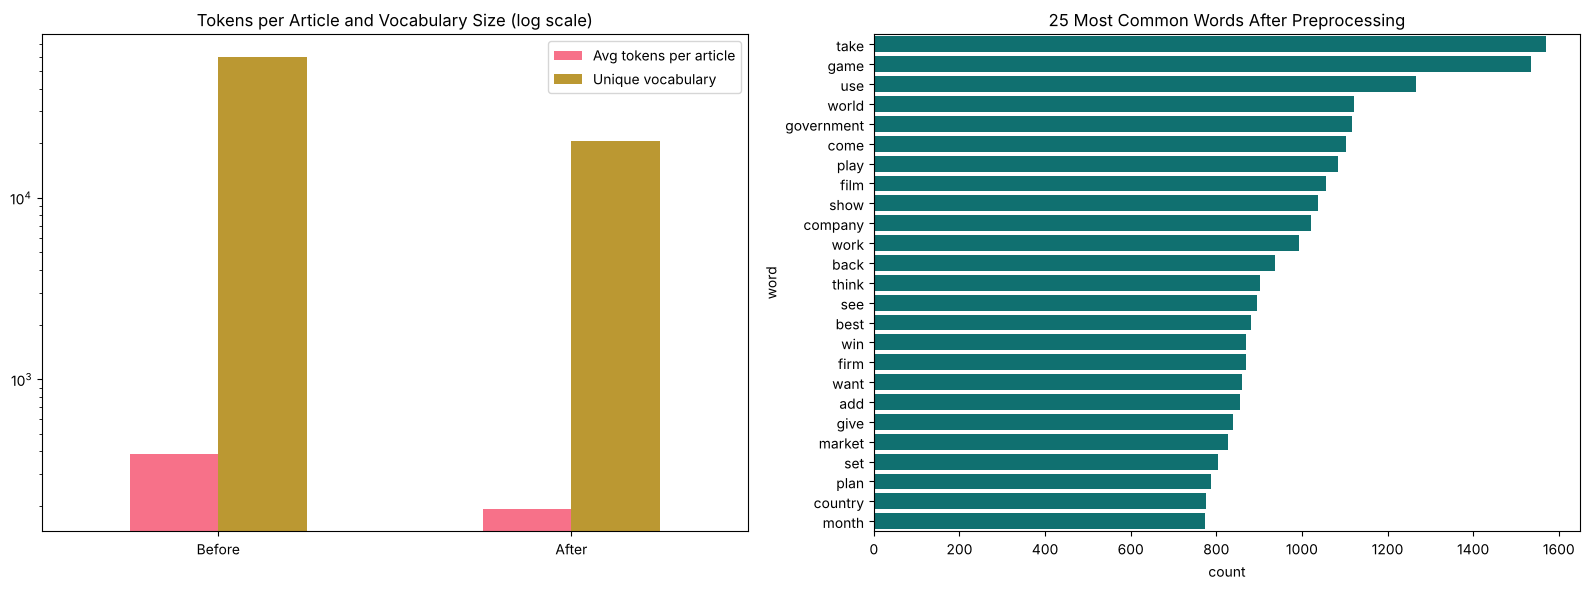

In [6]:
# Apply preprocessing to the dataset
print("🧹 Preprocessing all articles...")
start = time.time()

df['title_clean'] = df['title'].apply(clean_text)
df['content_clean'] = df['content'].apply(clean_text)
df['title_processed'] = df['title'].apply(preprocess_text)
df['content_processed'] = df['content'].apply(preprocess_text)

# Combine title and content for full article analysis
df['full_text'] = df['title'] + '. ' + df['content']
df['full_text_processed'] = df['full_text'].apply(preprocess_text)

print(f"✅ Preprocessing complete in {time.time() - start:.1f}s!")

# Show before and after examples
print("\n📝 BEFORE AND AFTER EXAMPLES")
print("=" * 60)
for i in range(3):
    print(f"\nExample {i+1} ({df.iloc[i]['category']}):")
    print(f"Original:  {df.iloc[i]['full_text'][:120]}...")
    print(f"Processed: {df.iloc[i]['full_text_processed'][:120]}...")

# Preprocessing impact analysis
raw_tokens = df['full_text'].str.lower().str.split()
proc_tokens = df['full_text_processed'].str.split()
raw_vocab = set(t for toks in raw_tokens for t in toks)
proc_vocab = set(t for toks in proc_tokens for t in toks)

impact = pd.DataFrame({
    'Before': [raw_tokens.str.len().mean(), df['full_text'].str.len().mean(), len(raw_vocab)],
    'After': [proc_tokens.str.len().mean(), df['full_text_processed'].str.len().mean(), len(proc_vocab)],
}, index=['Avg tokens per article', 'Avg characters per article', 'Unique vocabulary'])
impact['Reduction %'] = (1 - impact['After'] / impact['Before']) * 100
print("\n📉 PREPROCESSING IMPACT")
print("=" * 60)
print(impact.round(1))

# Most common words after preprocessing
word_freq = Counter(t for toks in proc_tokens for t in toks)
top_words = pd.DataFrame(word_freq.most_common(25), columns=['word', 'count'])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
impact[['Before', 'After']].iloc[[0, 2]].T.plot(kind='bar', ax=axes[0], logy=True, rot=0)
axes[0].set_title('Tokens per Article and Vocabulary Size (log scale)')
sns.barplot(data=top_words, y='word', x='count', ax=axes[1], color='teal')
axes[1].set_title('25 Most Common Words After Preprocessing')
plt.tight_layout()
plt.show()

### 📝 Preprocessing Findings

* The pipeline roughly **halves the number of tokens per article** (386 to 194) and shrinks the **vocabulary by 66%** (59,627 to 20,447 unique words). A smaller, denser vocabulary means fewer sparse features and faster, more stable models.
* Edge cases behave correctly: missing values, empty strings and number only strings return an empty string instead of crashing, HTML entities are decoded, contractions are expanded before punctuation is stripped, and accented words are normalized.
* Removing the extra news stop words (*said*, *mr*, *year*) matters: before we added them, *said* was the most frequent word in every category and told us nothing about the topic.
* **Trade off:** lowercasing and removing digits destroys information that NER and POS tagging need (capital letters, numbers, money). That is why those modules work on the original text.

## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

TF-IDF (Term Frequency times Inverse Document Frequency) scores a word highly when it is frequent in one article but rare across the corpus.

**TF-IDF Key Concepts:**
* **Term Frequency (TF):** how often a word appears in a document
* **Inverse Document Frequency (IDF):** how rare a word is across all documents
* **TF-IDF Score:** TF × IDF, balancing frequency with uniqueness

We first **optimize the vectorizer parameters** with cross validation, then use the winning configuration to study category specific vocabulary.

**💡 Business Value:** TF-IDF surfaces the most distinctive terms for each news category, which doubles as an explainable keyword profile for each desk.

In [7]:
# TF-IDF parameter optimization
# We compare vectorizer settings using 5 fold cross validation of a simple Logistic Regression.
# Only the training split is used here so the test set stays untouched for Module 7.
train_idx, test_idx = train_test_split(df.index, test_size=0.2, stratify=df['category'],
                                       random_state=RANDOM_STATE)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

tfidf_configs = {
    'Unigrams, 1k features':        dict(ngram_range=(1, 1), max_features=1000, min_df=2, max_df=0.8),
    'Unigrams, 5k features':        dict(ngram_range=(1, 1), max_features=5000, min_df=2, max_df=0.8),
    'Uni+bigrams, 5k (template)':   dict(ngram_range=(1, 2), max_features=5000, min_df=2, max_df=0.8),
    'Uni+bigrams, 5k, sublinear':   dict(ngram_range=(1, 2), max_features=5000, min_df=2, max_df=0.8, sublinear_tf=True),
    'Uni+bigrams, 10k, sublinear':  dict(ngram_range=(1, 2), max_features=10000, min_df=2, max_df=0.8, sublinear_tf=True),
    'Uni+bigrams, 10k, min_df=5':   dict(ngram_range=(1, 2), max_features=10000, min_df=5, max_df=0.8, sublinear_tf=True),
}

config_rows = []
for name, params in tfidf_configs.items():
    pipe = Pipeline([('tfidf', TfidfVectorizer(**params)),
                     ('clf', LogisticRegression(max_iter=2000, C=10))])
    scores = cross_val_score(pipe, df.loc[train_idx, 'full_text_processed'],
                             df.loc[train_idx, 'category'], cv=cv5, scoring='accuracy', n_jobs=-1)
    vocab = len(TfidfVectorizer(**params).fit(df.loc[train_idx, 'full_text_processed']).vocabulary_)
    config_rows.append({'Config': name, 'Vocab size': vocab,
                        'CV accuracy': scores.mean(), 'CV std': scores.std()})

tfidf_config_df = pd.DataFrame(config_rows).sort_values('CV accuracy', ascending=False)
print("🔧 TF-IDF PARAMETER OPTIMIZATION (5 fold CV on training split)")
print(tfidf_config_df.round(4).to_string(index=False))
best_tfidf_name = tfidf_config_df.iloc[0]['Config']
BEST_TFIDF_PARAMS = tfidf_configs[best_tfidf_name]
print(f"\n🥇 Best configuration: {best_tfidf_name} -> {BEST_TFIDF_PARAMS}")

🔧 TF-IDF PARAMETER OPTIMIZATION (5 fold CV on training split)
                     Config  Vocab size  CV accuracy  CV std
Uni+bigrams, 10k, sublinear       10000       0.9819  0.0091
 Uni+bigrams, 10k, min_df=5        8557       0.9812  0.0081
 Uni+bigrams, 5k, sublinear        5000       0.9800  0.0083
      Unigrams, 5k features        5000       0.9744  0.0100
 Uni+bigrams, 5k (template)        5000       0.9731  0.0090
      Unigrams, 1k features        1000       0.9712  0.0105

🥇 Best configuration: Uni+bigrams, 10k, sublinear -> {'ngram_range': (1, 2), 'max_features': 10000, 'min_df': 2, 'max_df': 0.8, 'sublinear_tf': True}


In [8]:
# Create TF-IDF vectorizer with the optimized parameters
tfidf_vectorizer = TfidfVectorizer(**BEST_TFIDF_PARAMS)

# Fit and transform the processed text (whole corpus, for exploratory analysis)
print("🔢 Creating TF-IDF features...")
tfidf_matrix = tfidf_vectorizer.fit_transform(df['full_text_processed'])
feature_names = tfidf_vectorizer.get_feature_names_out()

print(f"✅ TF-IDF matrix created!")
print(f"📊 Shape: {tfidf_matrix.shape}")
print(f"📝 Vocabulary size: {len(feature_names)}")
print(f"🔗 Bigrams in vocabulary: {sum(' ' in f for f in feature_names)}")
print(f"🔢 Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")

# Convert to DataFrame for easier analysis
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
tfidf_df['category'] = df['category'].values

print("\n🔍 Sample TF-IDF features (highest scoring terms of the first article):")
first = tfidf_df.drop(columns='category').iloc[0]
print(first[first > 0].sort_values(ascending=False).head(10).round(4))

🔢 Creating TF-IDF features...


✅ TF-IDF matrix created!
📊 Shape: (2000, 10000)
📝 Vocabulary size: 10000
🔗 Bigrams in vocabulary: 3488
🔢 Sparsity: 98.64%

🔍 Sample TF-IDF features (highest scoring terms of the first article):
childcare             0.1980
maternity             0.1848
kennedy               0.1594
woman                 0.1547
maternity pay         0.1478
national insurance    0.1311
pension               0.1308
flexible              0.1262
female                0.1239
manifesto             0.1219
Name: 0, dtype: float64


🏷️ TOP TF-IDF TERMS BY CATEGORY

📰 BUSINESS: company (0.035), firm (0.033), market (0.032), rise (0.028), bank (0.028), share (0.027), growth (0.027), price (0.025), economy (0.025), sale (0.024)



📰 ENTERTAINMENT: film (0.058), star (0.040), award (0.039), show (0.029), best (0.028), music (0.028), include (0.026), actor (0.025), band (0.024), oscar (0.023)

📰 POLITICS: labour (0.044), election (0.042), party (0.040), government (0.039), blair (0.038), minister (0.037), tory (0.037), plan (0.028), leader (0.025), secretary (0.025)

📰 SPORTS: game (0.036), win (0.035), play (0.034), player (0.031), match (0.030), team (0.027), cup (0.025), champion (0.025), injury (0.024), coach (0.024)

📰 TECHNOLOGY: use (0.040), technology (0.037), user (0.036), computer (0.032), mobile (0.029), software (0.028), phone (0.027), service (0.027), game (0.027), net (0.026)


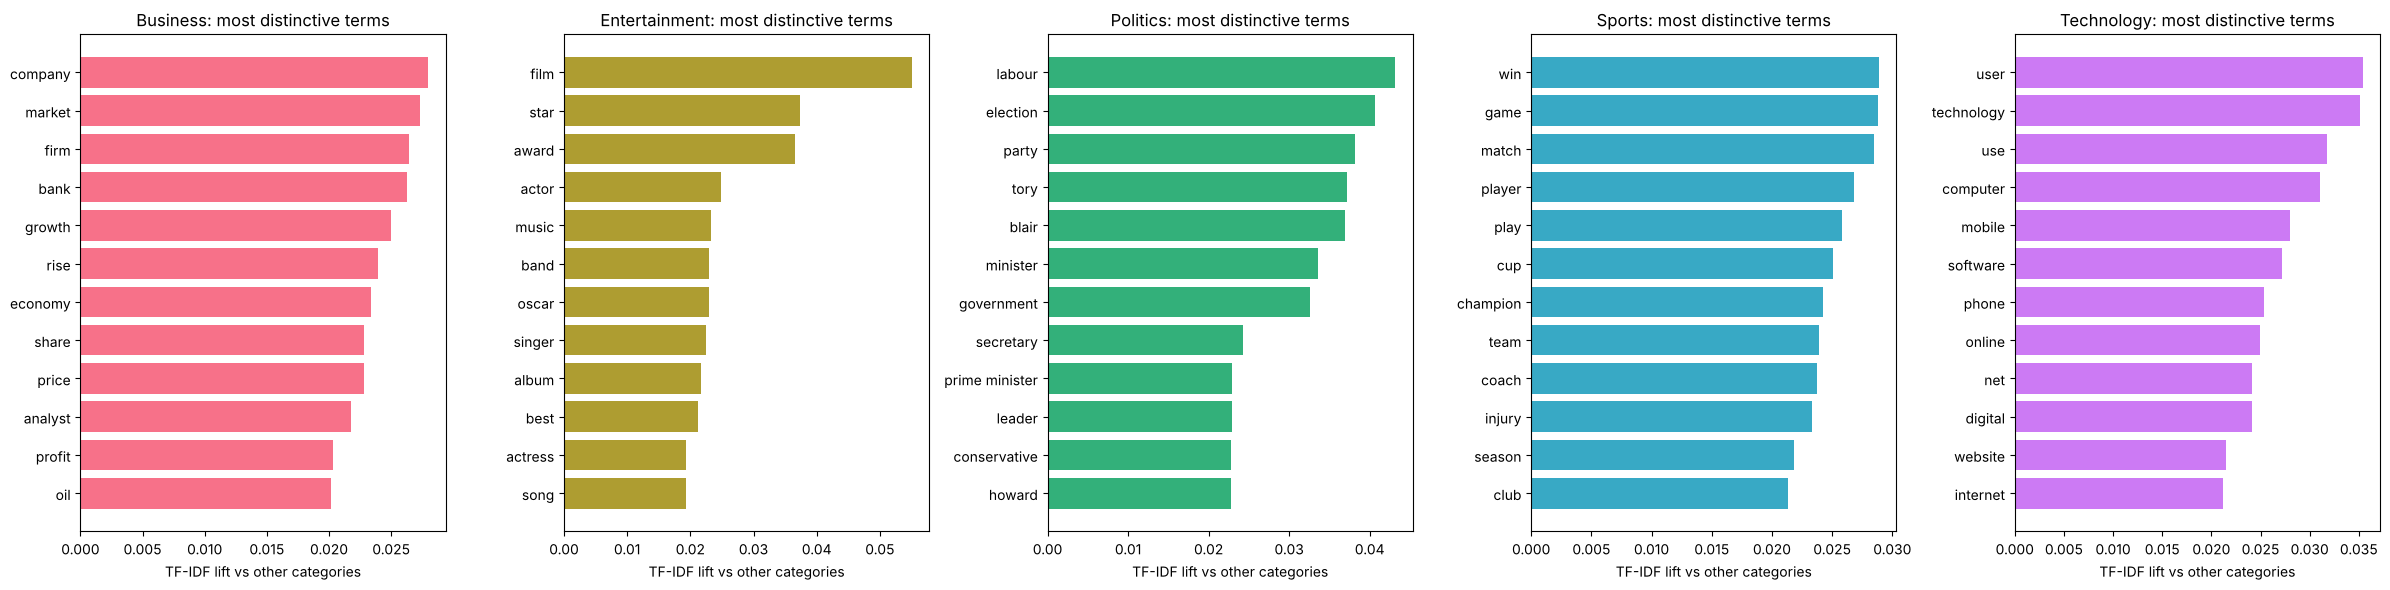

In [9]:
# Analyze most important terms per category
def get_top_tfidf_terms(category, n_terms=10, distinctive=False):
    '''
    Top TF-IDF terms for a category.
    distinctive=False: highest mean TF-IDF within the category.
    distinctive=True:  highest lift = category mean minus mean of all other categories,
                       which removes words that are common everywhere.
    '''
    features = tfidf_df.drop(columns='category')
    in_cat = tfidf_df['category'] == category
    cat_mean = features[in_cat].mean()
    if distinctive:
        cat_mean = cat_mean - features[~in_cat].mean()
    return cat_mean.sort_values(ascending=False).head(n_terms)

print("🏷️ TOP TF-IDF TERMS BY CATEGORY")
print("=" * 50)
categories = CATEGORY_ORDER
category_terms = {}
for category in categories:
    top_terms = get_top_tfidf_terms(category, n_terms=10)
    category_terms[category] = top_terms
    print(f"\n📰 {category.upper()}: " + ', '.join(f"{t} ({s:.3f})" for t, s in top_terms.items()))

# Bar charts of the most distinctive terms per category
fig, axes = plt.subplots(1, 5, figsize=(24, 6))
for ax, category in zip(axes, categories):
    terms = get_top_tfidf_terms(category, n_terms=12, distinctive=True)
    ax.barh(terms.index[::-1], terms.values[::-1], color=CAT_COLORS[category])
    ax.set_title(f'{category}: most distinctive terms')
    ax.set_xlabel('TF-IDF lift vs other categories')
plt.tight_layout()
plt.show()

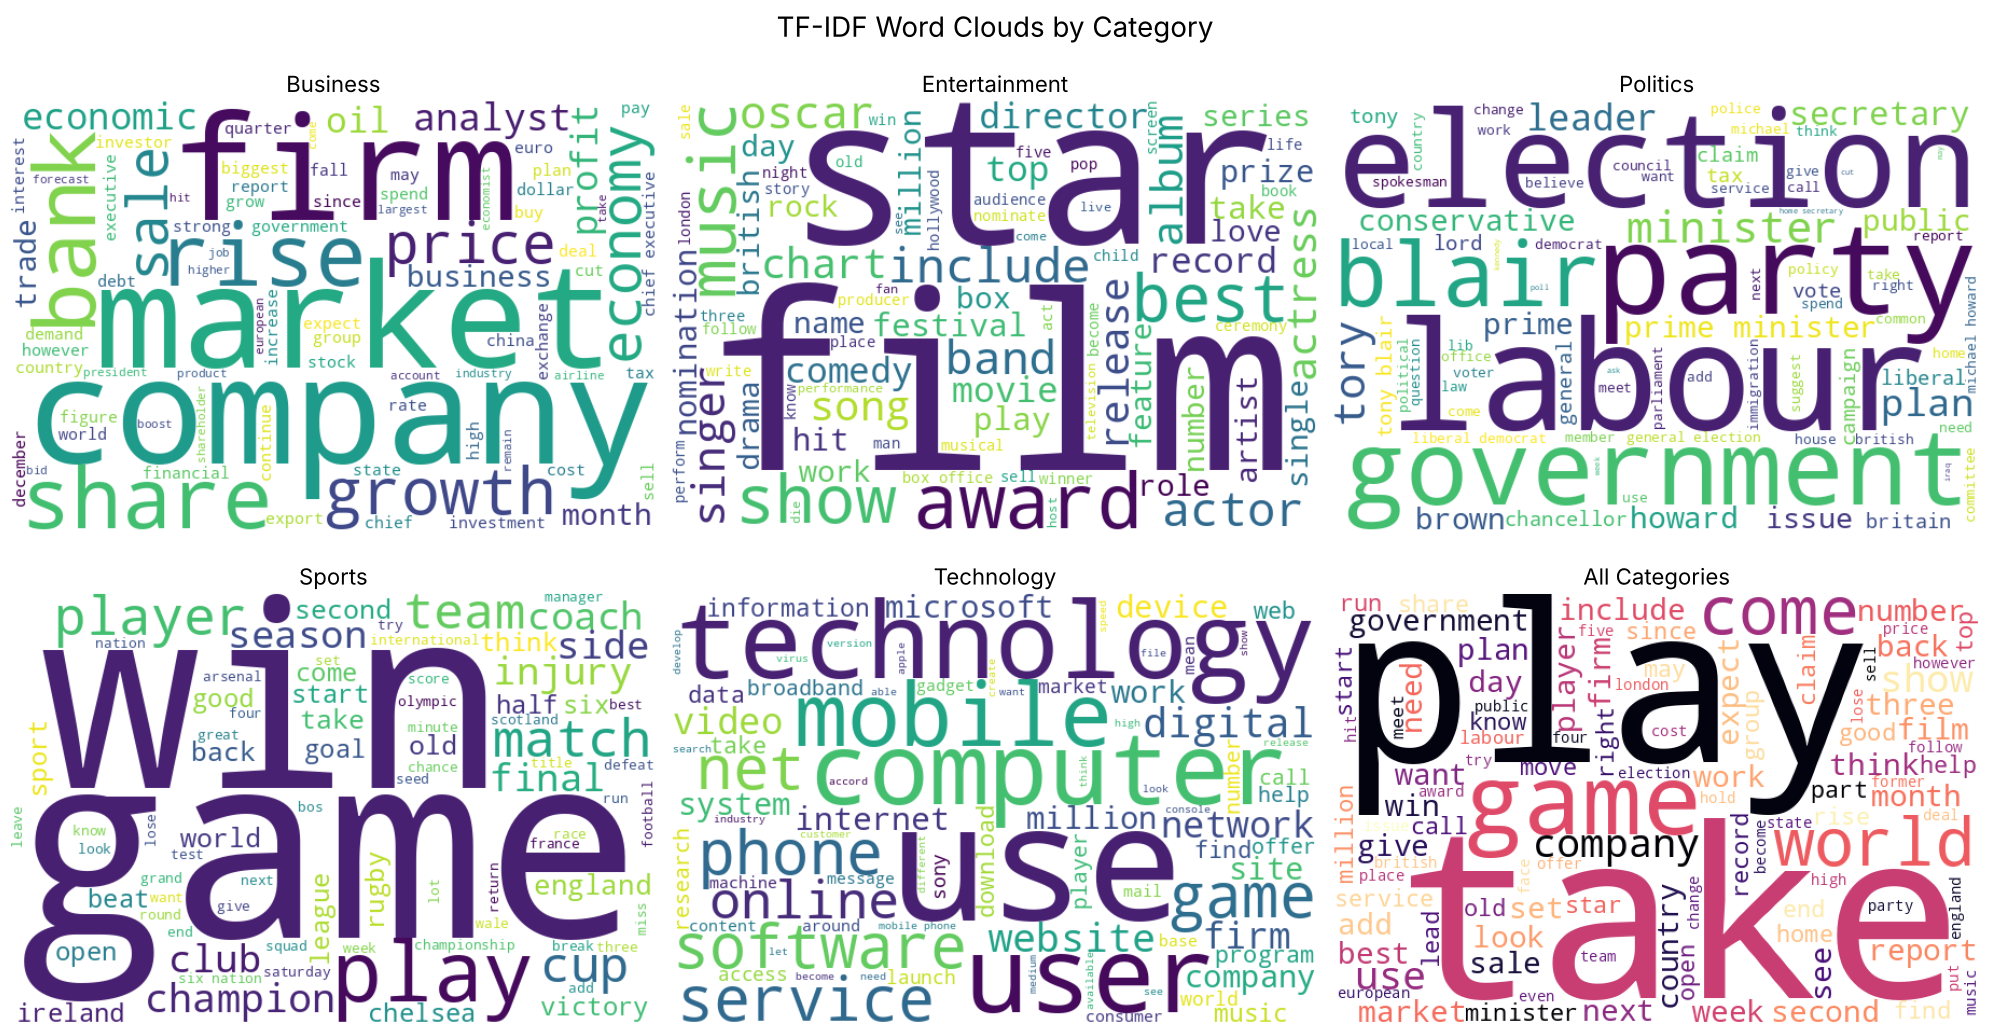

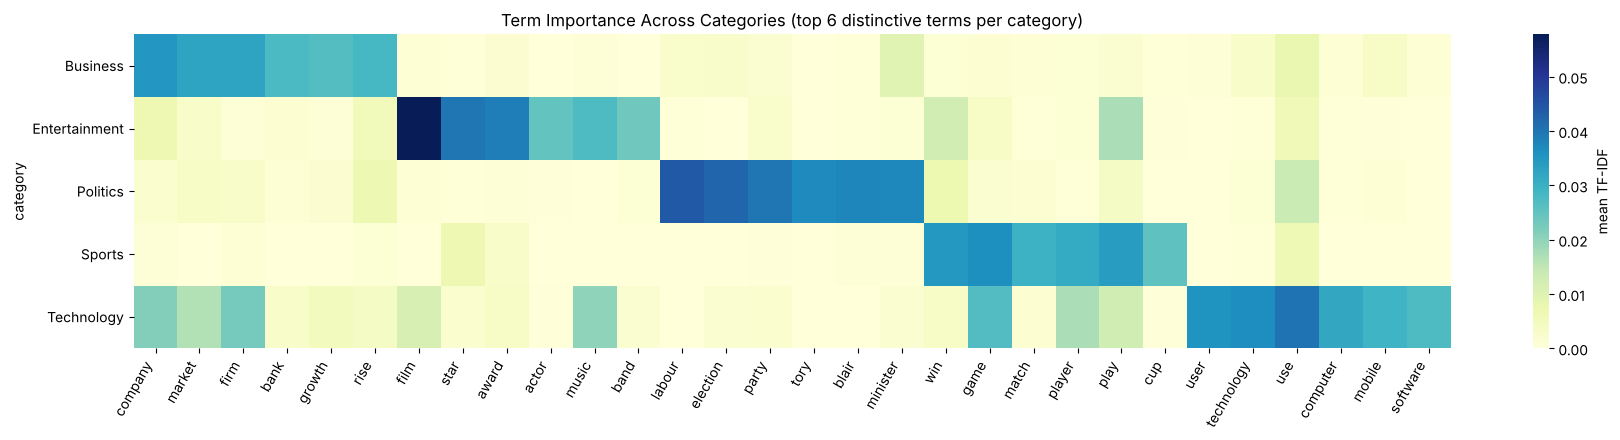

In [10]:
# Word clouds for each category (sized by mean TF-IDF score)
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for ax, category in zip(axes.flat, categories):
    weights = get_top_tfidf_terms(category, n_terms=80).to_dict()
    wc = WordCloud(width=600, height=400, background_color='white', colormap='viridis',
                   random_state=RANDOM_STATE).generate_from_frequencies(weights)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(category, fontsize=16)
    ax.axis('off')

# Overall word cloud in the last panel
overall = tfidf_df.drop(columns='category').mean().sort_values(ascending=False).head(100).to_dict()
axes.flat[-1].imshow(WordCloud(width=600, height=400, background_color='white', colormap='magma',
                               random_state=RANDOM_STATE).generate_from_frequencies(overall))
axes.flat[-1].set_title('All Categories', fontsize=16)
axes.flat[-1].axis('off')
plt.suptitle('TF-IDF Word Clouds by Category', fontsize=20)
plt.tight_layout()
plt.show()

# Heatmap of term importance across categories
heat_terms = []
for category in categories:
    heat_terms += list(get_top_tfidf_terms(category, n_terms=6, distinctive=True).index)
heat_terms = list(dict.fromkeys(heat_terms))
heat_data = tfidf_df.groupby('category')[heat_terms].mean()
plt.figure(figsize=(18, 4.5))
sns.heatmap(heat_data, cmap='YlGnBu', annot=False, cbar_kws={'label': 'mean TF-IDF'})
plt.title('Term Importance Across Categories (top 6 distinctive terms per category)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

📈 TOP 20 TERMS BY CHI SQUARED (most informative for classification)
      term  chi2  p_value  strongest_in
      film 73.22      0.0 Entertainment
    labour 63.20      0.0      Politics
      tory 60.42      0.0      Politics
      user 56.86      0.0    Technology
  election 56.70      0.0      Politics
     blair 55.41      0.0      Politics
     party 50.52      0.0      Politics
technology 47.39      0.0    Technology
  computer 46.88      0.0    Technology
     award 45.42      0.0 Entertainment
      star 44.81      0.0 Entertainment
  software 42.66      0.0    Technology
     actor 39.20      0.0 Entertainment
     match 37.39      0.0        Sports
     oscar 37.21      0.0 Entertainment
    mobile 37.09      0.0    Technology
  minister 36.87      0.0      Politics
       cup 36.47      0.0        Sports
    singer 35.95      0.0 Entertainment
     coach 35.05      0.0        Sports

Terms significant at p < 0.01: 224 of 10000


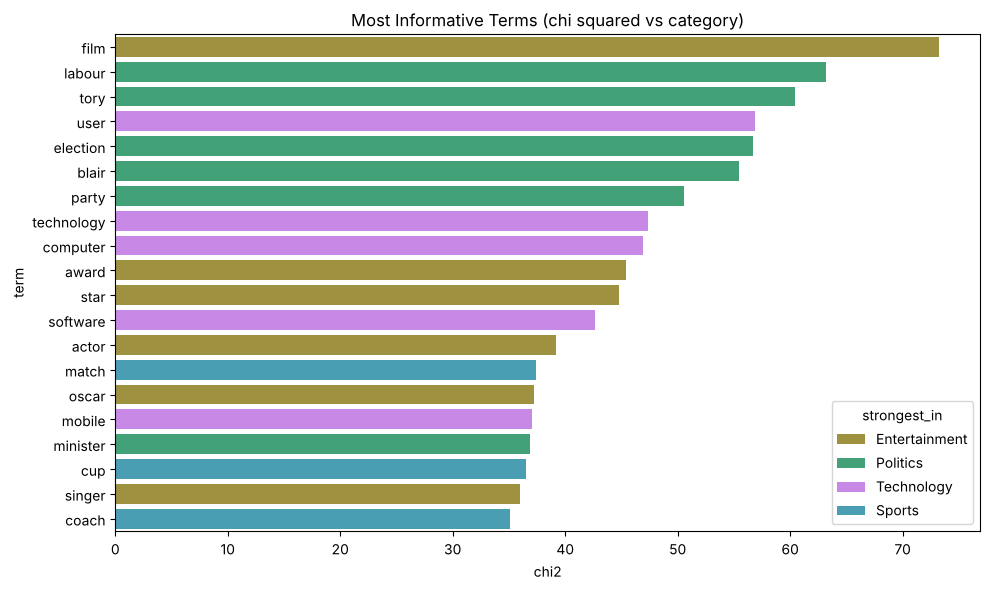

In [11]:
# Feature importance analysis: chi squared test between each term and the category label
chi_scores, p_values = chi2(tfidf_matrix, df['category'])
chi_df = (pd.DataFrame({'term': feature_names, 'chi2': chi_scores, 'p_value': p_values})
          .sort_values('chi2', ascending=False))
# Attach the category where each term is strongest
cat_means = tfidf_df.groupby('category')[chi_df['term'].head(20).tolist()].mean()
top_chi = chi_df.head(20).copy()
top_chi['strongest_in'] = top_chi['term'].map(cat_means.idxmax())

print("📈 TOP 20 TERMS BY CHI SQUARED (most informative for classification)")
print(top_chi.round(2).to_string(index=False))
print(f"\nTerms significant at p < 0.01: {(chi_df['p_value'] < 0.01).sum()} of {len(chi_df)}")

plt.figure(figsize=(10, 6))
sns.barplot(data=top_chi, x='chi2', y='term', hue='strongest_in', dodge=False, palette=CAT_COLORS)
plt.title('Most Informative Terms (chi squared vs category)')
plt.tight_layout()
plt.show()

### 📝 TF-IDF Findings

* **Parameter optimization paid off.** Adding bigrams, sublinear term frequency (log scaling of counts) and a larger 10,000 term vocabulary raised cross validated accuracy from 97.3% (template settings) to **98.2%**. Sublinear TF helps because a word repeated 10 times in one article is not 10 times more important.
* **Each category has a clear vocabulary.** Business: *company, firm, market, bank, share, growth*. Entertainment: *film, star, award, music, oscar*. Politics: *labour, election, party, government, blair, tory*. Sports: *game, win, player, match, cup, coach*. Technology: *technology, user, computer, mobile, software*.
* **Bigrams capture concepts** single words miss, such as *prime minister*, *box office*, *maternity pay* and *national insurance*.
* **Ambiguity shows up too:** *game* scores highly in both Sports and Technology (video games), and *play* appears in Sports and Entertainment. These shared words explain most of the classifier's later mistakes.
* The chi squared test confirms that topic words such as *film, labour, tory, user* and *election* are the most informative features, with Politics and Entertainment owning many of the top 20.

## 🏷️ Part of Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

POS tagging (NLTK Penn Treebank tagger on the original cased text) reveals differences in writing style between categories.

**POS Analysis Applications:**
* **Writing Style Detection:** categories may favor different grammatical patterns
* **Content Quality Assessment:** proper noun density, adjective usage, numeric density
* **Feature Engineering:** POS proportions become extra classifier features

**💡 Hypothesis:** Sports articles use more past tense action verbs, while business articles use more numbers (CD) and proper nouns.

In [12]:
def analyze_pos_patterns(text):
    '''
    Tokenize and POS tag a text with NLTK, returning the proportion of each Penn Treebank tag
    (punctuation excluded so proportions are relative to words).
    '''
    if not text or pd.isna(text):
        return {}
    tokens = [t for t in word_tokenize(str(text)) if re.search(r'[A-Za-z0-9]', t)]
    pos_tags = pos_tag(tokens)
    total_words = len(pos_tags)
    if total_words == 0:
        return {}
    pos_counts = Counter(tag for _, tag in pos_tags)
    return {pos: count / total_words for pos, count in pos_counts.items()}

def pos_tag_sequence(text):
    # Tag sequence used for grammatical pattern (n gram) mining
    tokens = [t for t in word_tokenize(str(text)) if re.search(r'[A-Za-z0-9]', t)]
    return [tag for _, tag in pos_tag(tokens)]

print("🏷️ Analyzing POS patterns...")
start = time.time()
pos_results, pos_sequences = [], []
for _, row in df.iterrows():
    seq = pos_tag_sequence(row['full_text'])
    pos_sequences.append(seq)
    counts = Counter(seq)
    props = {tag: c / len(seq) for tag, c in counts.items()}
    props['category'] = row['category']
    props['article_id'] = row['article_id']
    pos_results.append(props)

pos_df = pd.DataFrame(pos_results).fillna(0)
print(f"✅ POS analysis complete in {time.time() - start:.1f}s!")
print(f"📊 Found {len(pos_df.columns) - 2} different POS tags")
print("\n📝 Sample POS analysis (first 5 articles, selected tags):")
print(pos_df[['article_id', 'category', 'NN', 'NNP', 'VBD', 'JJ', 'CD']].head().round(3))

🏷️ Analyzing POS patterns...


✅ POS analysis complete in 29.8s!
📊 Found 36 different POS tags

📝 Sample POS analysis (first 5 articles, selected tags):
   article_id    category     NN    NNP    VBD     JJ     CD
0           1    Politics  0.148  0.080  0.032  0.070  0.020
1           2  Technology  0.134  0.136  0.080  0.054  0.017
2           3      Sports  0.141  0.200  0.037  0.081  0.015
3           4    Business  0.178  0.166  0.043  0.079  0.047
4           5    Business  0.183  0.082  0.033  0.087  0.007


📊 POS PATTERNS BY CATEGORY

🎯 Key POS patterns by category (proportion of words):
                   NN     NNS     NNP    NNPS      VB     VBD     VBG     VBN  \
category                                                                        
Business       0.1589  0.0694  0.1152  0.0018  0.0336  0.0425  0.0211  0.0287   
Entertainment  0.1453  0.0445  0.1752  0.0016  0.0260  0.0471  0.0191  0.0301   
Politics       0.1397  0.0597  0.1186  0.0039  0.0444  0.0495  0.0220  0.0305   
Sports         0.1233  0.0327  0.1659  0.0021  0.0381  0.0461  0.0191  0.0245   
Technology     0.1480  0.0804  0.0878  0.0010  0.0436  0.0308  0.0248  0.0279   

                  VBP     VBZ      JJ     JJR     JJS      RB     RBR     RBS  \
category                                                                        
Business       0.0148  0.0259  0.0710  0.0048  0.0036  0.0291  0.0019  0.0005   
Entertainment  0.0149  0.0246  0.0617  0.0023  0.0052  0.0281  0.0010  0.0008   
Politics       0.0188  0.0

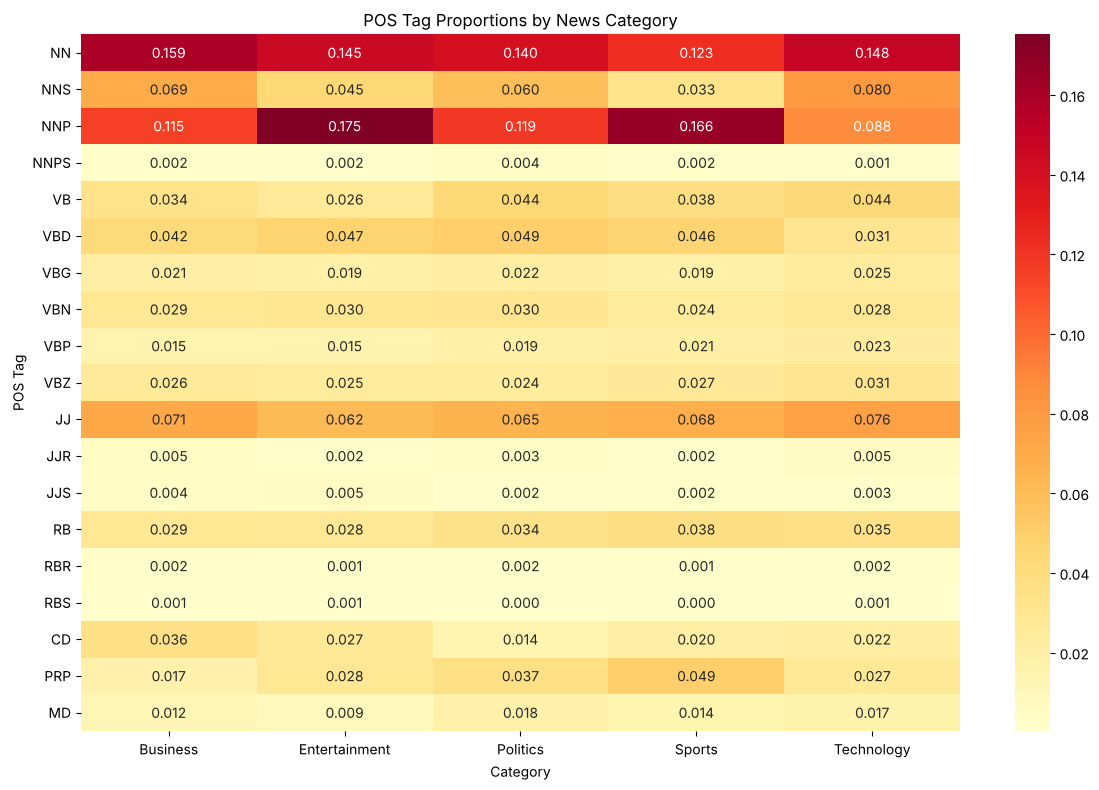


🧪 KRUSKAL WALLIS TEST: does each word class differ across categories?
  Common nouns         H =  1051.7   p = 2.19e-226   highest in Technology
  Proper nouns         H =   546.7   p = 5.34e-117   highest in Entertainment
  Verbs                H =   226.0   p = 9.59e-48   highest in Politics
  Past tense verbs     H =   175.1   p = 8.21e-37   highest in Politics
  Present tense verbs  H =   173.0   p = 2.41e-36   highest in Technology
  Adjectives           H =   171.7   p = 4.52e-36   highest in Technology
  Adverbs              H =   145.1   p = 2.26e-30   highest in Sports
  Numbers              H =   388.7   p = 7.81e-83   highest in Business
  Pronouns             H =   461.5   p = 1.41e-98   highest in Sports
  Modals               H =   237.9   p = 2.66e-50   highest in Politics


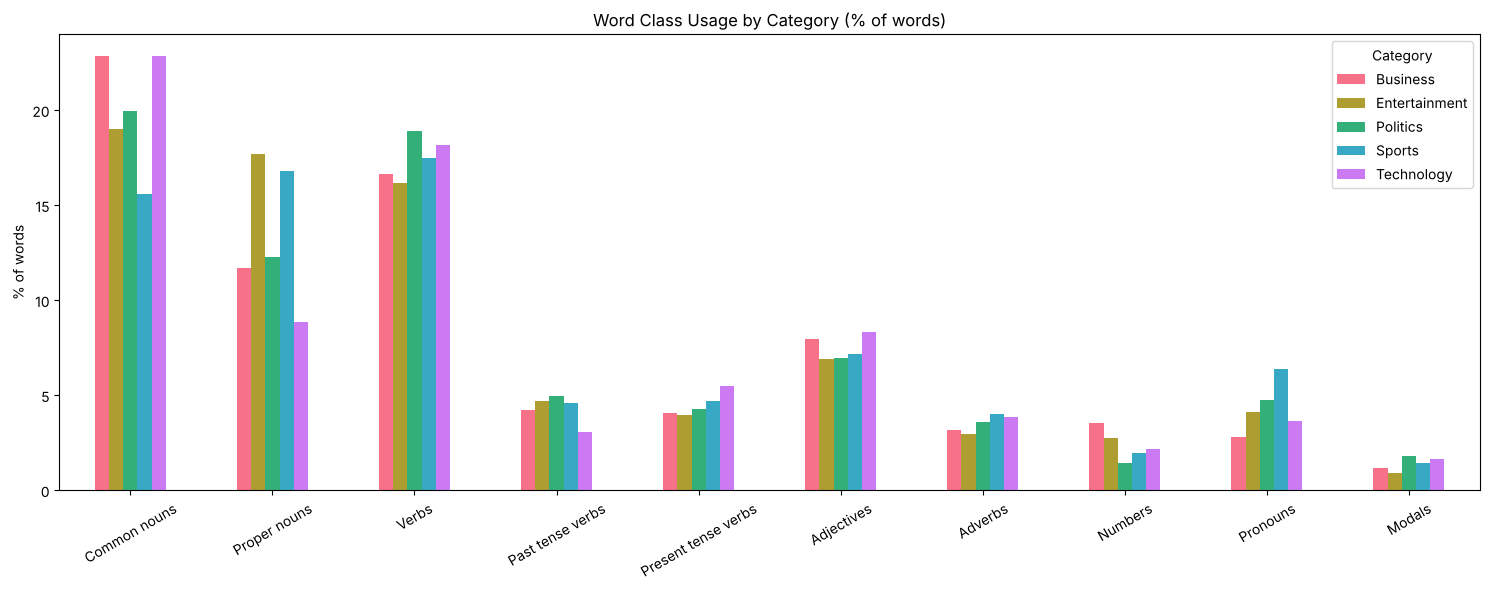

In [13]:
# Analyze POS patterns by category
print("📊 POS PATTERNS BY CATEGORY")
print("=" * 50)
pos_by_category = pos_df.drop(columns='article_id').groupby('category').mean()

major_pos = ['NN', 'NNS', 'NNP', 'NNPS', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
             'JJ', 'JJR', 'JJS', 'RB', 'RBR', 'RBS', 'CD', 'PRP', 'MD']
available_pos = [pos for pos in major_pos if pos in pos_by_category.columns]
pos_summary = pos_by_category[available_pos]

print("\n🎯 Key POS patterns by category (proportion of words):")
print(pos_summary.round(4))

plt.figure(figsize=(12, 8))
sns.heatmap(pos_summary.T, annot=True, cmap='YlOrRd', fmt='.3f')
plt.title('POS Tag Proportions by News Category')
plt.xlabel('Category')
plt.ylabel('POS Tag')
plt.tight_layout()
plt.show()

# Group fine grained tags into broader word classes
POS_GROUPS = {
    'Common nouns': ['NN', 'NNS'], 'Proper nouns': ['NNP', 'NNPS'],
    'Verbs': ['VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ'], 'Past tense verbs': ['VBD'],
    'Present tense verbs': ['VBP', 'VBZ'], 'Adjectives': ['JJ', 'JJR', 'JJS'],
    'Adverbs': ['RB', 'RBR', 'RBS'], 'Numbers': ['CD'], 'Pronouns': ['PRP', 'PRP$'], 'Modals': ['MD'],
}
pos_groups_df = pd.DataFrame({g: pos_df[[t for t in tags if t in pos_df]].sum(axis=1)
                              for g, tags in POS_GROUPS.items()})
pos_groups_df['category'] = pos_df['category']
group_means = pos_groups_df.groupby('category').mean()

# Statistical test: do categories really differ? (Kruskal Wallis H test per word class)
print("\n🧪 KRUSKAL WALLIS TEST: does each word class differ across categories?")
for g in POS_GROUPS:
    samples = [pos_groups_df.loc[pos_groups_df['category'] == c, g] for c in CATEGORY_ORDER]
    h, p = kruskal(*samples)
    print(f"  {g:20s} H = {h:7.1f}   p = {p:.2e}   highest in {group_means[g].idxmax()}")

(group_means * 100).T.plot(kind='bar', figsize=(15, 6), color=[CAT_COLORS[c] for c in group_means.index])
plt.title('Word Class Usage by Category (% of words)')
plt.ylabel('% of words')
plt.xticks(rotation=30)
plt.legend(title='Category')
plt.tight_layout()
plt.show()

In [14]:
# Answering the analysis questions directly from the data
pc = pos_summary
proper = pc['NNP'] + pc.get('NNPS', 0)
action = pc['VB'] + pc['VBD'] + pc['VBG']
print("💡 ANALYSIS QUESTIONS")
print(f"1. Highest proper noun share (NNP/NNPS): {proper.idxmax()} ({proper.max():.2%}), lowest: {proper.idxmin()} ({proper.min():.2%})")
print(f"2. Most action verbs (VB, VBD, VBG): {action.idxmax()} ({action.max():.2%}), least: {action.idxmin()} ({action.min():.2%})")
print(f"3. Adjective (JJ) share ranges from {pc['JJ'].min():.2%} ({pc['JJ'].idxmin()}) to {pc['JJ'].max():.2%} ({pc['JJ'].idxmax()})")
print(f"4. Number (CD) share ranges from {pc['CD'].min():.2%} ({pc['CD'].idxmin()}) to {pc['CD'].max():.2%} ({pc['CD'].idxmax()})")

nouns = pc[['NN', 'NNS', 'NNP', 'NNPS']].sum(axis=1)
verbs = pc[['VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ']].sum(axis=1)
print("\nNoun to verb ratio by category:")
print((nouns / verbs).sort_values(ascending=False).round(2).to_string())

# Grammatical pattern mining: most characteristic POS trigrams per category
print("\n🔤 MOST CHARACTERISTIC POS TRIGRAMS PER CATEGORY (lift over corpus rate)")
tri_by_cat = defaultdict(Counter)
for seq, cat in zip(pos_sequences, df['category']):
    tri_by_cat[cat].update(zip(seq, seq[1:], seq[2:]))
tri_all = sum(tri_by_cat.values(), Counter())
total_all = sum(tri_all.values())
for cat in CATEGORY_ORDER:
    total_cat = sum(tri_by_cat[cat].values())
    lifts = {t: (c / total_cat) / (tri_all[t] / total_all)
             for t, c in tri_by_cat[cat].items() if tri_all[t] >= 150}
    top = sorted(lifts.items(), key=lambda x: -x[1])[:4]
    print(f"  {cat:13s}: " + ' | '.join(f"{' '.join(t)} (x{l:.2f})" for t, l in top))

💡 ANALYSIS QUESTIONS
1. Highest proper noun share (NNP/NNPS): Entertainment (17.68%), lowest: Technology (8.87%)
2. Most action verbs (VB, VBD, VBG): Politics (11.59%), least: Entertainment (9.21%)
3. Adjective (JJ) share ranges from 6.17% (Entertainment) to 7.57% (Technology)
4. Number (CD) share ranges from 1.45% (Politics) to 3.55% (Business)

Noun to verb ratio by category:
category
Entertainment    2.27
Business         2.07
Sports           1.85
Technology       1.74
Politics         1.70

🔤 MOST CHARACTERISTIC POS TRIGRAMS PER CATEGORY (lift over corpus rate)
  Business     : TO CD IN (x2.94) | CD TO CD (x2.89) | CD IN CD (x2.82) | POS JJS NN (x2.74)
  Entertainment: JJS NN NN (x3.45) | JJS JJ NN (x3.34) | NN CD IN (x2.73) | NN POS NNP (x2.68)
  Politics     : IN DT NNPS (x1.98) | EX MD VB (x1.97) | NNP VBZ VBD (x1.86) | EX VBD DT (x1.81)
  Sports       : NNP CD NNP (x2.91) | NNP CC PRP (x2.76) | CC NNP VBD (x2.66) | CC PRP VBP (x2.60)
  Technology   : NNS WDT VBP (x2.63) | NNS 

### 📝 POS Findings: writing style differs by category

Every word class differs significantly across categories (Kruskal Wallis p values far below 0.001), so these differences are not random noise.

1. **Proper nouns:** Entertainment (17.7%) and Sports (16.8%) are full of names of stars, clubs and players. Technology has the fewest (8.9%) because it talks about products and concepts in general terms.
2. **Action verbs:** Politics uses the most verbs overall and the most past tense verbs (reporting what politicians *said* and *did*), and the most modal verbs (*would, could, should*), reflecting talk about plans and possibilities. Entertainment uses the fewest action verbs and has the highest noun to verb ratio (2.27), a descriptive, name heavy style.
3. **Adjectives:** Technology uses the most (7.6%), describing products (*new, digital, mobile, faster*); Entertainment the fewest.
4. **Numbers:** Business is by far the most numeric (3.6% of words, more than double Politics at 1.5%). Its signature POS trigrams are number patterns such as *CD TO CD* ("from 3% to 5%").
5. **Other style markers:** Sports has the most pronouns (4.9%) and adverbs, typical of narrative match reports and quotes. Technology's signature trigrams contain relative pronouns (*NNS WDT VBP*, "users who want"), showing explanatory writing. Entertainment over uses superlatives (*JJS NN NN*, "best film award").

**Hypothesis check:** business articles do have more numbers, as predicted. Sports articles do not have the most action verbs; Politics does. Sports instead stands out for names and pronouns.

## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

spaCy's dependency parser tells us how words relate to each other, not just which words are present.

**Dependency Parsing Applications:**
* **Relationship Extraction:** connections between entities
* **Event Detection:** who did what to whom (subject, verb, object triples)
* **Information Extraction:** structured facts from unstructured text

We parse every article **once** with nlp.pipe (batched, efficient on the Colab CPU) and reuse the parsed documents for syntax features, semantic roles, NER (Module 8) and classifier features (Module 7).

**💡 Business Value:** Sentence structure lets us extract precise events such as *Verizon* (agent) *acquired* (action) *MCI* (patient), which keyword search alone cannot do.

In [15]:
# Parse all articles once with spaCy (about 2 to 3 minutes on a Colab CPU)
print("🌳 Parsing all articles with spaCy...")
start = time.time()
docs = list(nlp.pipe(df['full_text'].tolist(), batch_size=64))
print(f"✅ Parsed {len(docs)} articles in {time.time() - start:.1f}s")

def tree_depth(token):
    # Depth of a token in its dependency tree (root = 0)
    # (compare indices, not objects: spaCy creates a new Token object on every .head access)
    depth = 0
    while token.head.i != token.i:
        token = token.head
        depth += 1
    return depth

SUBORDINATE_DEPS = {'advcl', 'ccomp', 'xcomp', 'acl', 'relcl', 'csubj'}

def extract_syntactic_features(text=None, doc=None):
    '''
    Extract syntactic features using spaCy dependency parsing.
    Pass either raw text or an already parsed spaCy doc.
    Returns counts, complexity measures, noun phrases, subjects, objects and dependency counts.
    '''
    if doc is None:
        if not text or pd.isna(text):
            return {}
        doc = nlp(str(text))

    sents = list(doc.sents)
    words = [t for t in doc if not t.is_space and not t.is_punct]
    features = {
        'num_sentences': len(sents),
        'num_tokens': len(words),
        'dependency_relations': [t.dep_ for t in words],
        'noun_phrases': [chunk.text.lower() for chunk in doc.noun_chunks],
        'verb_phrases': [],
        'subjects': [t.text.lower() for t in doc if t.dep_ in ('nsubj', 'nsubjpass')],
        'objects': [t.text.lower() for t in doc if t.dep_ in ('dobj', 'iobj', 'pobj')],
    }
    # Verb phrases: verb lemma plus its particle / direct object (e.g. "cut rate", "take over")
    for t in doc:
        if t.pos_ == 'VERB':
            comps = [c.lemma_.lower() for c in t.children if c.dep_ in ('prt', 'dobj')]
            features['verb_phrases'].append(' '.join([t.lemma_.lower()] + comps))

    n_sent = max(len(sents), 1)
    features['dependency_counts'] = dict(Counter(features['dependency_relations']))
    features['avg_sentence_length'] = len(words) / n_sent
    features['avg_tree_depth'] = np.mean([max(tree_depth(t) for t in s) for s in sents]) if sents else 0
    features['subordinate_per_sentence'] = sum(t.dep_ in SUBORDINATE_DEPS for t in doc) / n_sent
    features['passive_per_sentence'] = sum(t.dep_ in ('nsubjpass', 'auxpass') for t in doc) / n_sent / 2
    features['noun_chunks_per_sentence'] = len(features['noun_phrases']) / n_sent
    return features

syntactic_results = []
for doc, (_, row) in zip(docs, df.iterrows()):
    f = extract_syntactic_features(doc=doc)
    f['category'] = row['category']
    f['article_id'] = row['article_id']
    syntactic_results.append(f)

syntax_cols = ['num_sentences', 'avg_sentence_length', 'avg_tree_depth',
               'subordinate_per_sentence', 'passive_per_sentence', 'noun_chunks_per_sentence']
syntax_df = pd.DataFrame([{k: r[k] for k in syntax_cols + ['category', 'article_id']}
                          for r in syntactic_results])

print("\n📐 SYNTACTIC COMPLEXITY BY CATEGORY (means)")
print(syntax_df.groupby('category')[syntax_cols].mean().round(2))

for i, result in enumerate(syntactic_results[:3]):
    print(f"\n📰 Article {i+1} ({result['category']}): {df.iloc[i]['title']}")
    print(f"  Sentences: {result['num_sentences']}, tokens: {result['num_tokens']}")
    print(f"  Noun phrases: {result['noun_phrases'][:4]}")
    print(f"  Verb phrases: {result['verb_phrases'][:4]}")
    print(f"  Subjects: {result['subjects'][:4]}")
    print(f"  Objects: {result['objects'][:4]}")

🌳 Parsing all articles with spaCy...


✅ Parsed 2000 articles in 91.6s



📐 SYNTACTIC COMPLEXITY BY CATEGORY (means)
               num_sentences  avg_sentence_length  avg_tree_depth  \
category                                                            
Business               16.76                20.23            5.84   
Entertainment          17.77                19.87            5.69   
Politics               22.32                21.17            6.12   
Sports                 18.13                18.72            5.30   
Technology             25.92                20.62            6.05   

               subordinate_per_sentence  passive_per_sentence  \
category                                                        
Business                           1.33                  0.19   
Entertainment                      1.19                  0.26   
Politics                           1.78                  0.27   
Sports                             1.22                  0.16   
Technology                         1.59                  0.23   

               n

In [16]:
# Visualize dependency parsing for a sample sentence
sample_sentence = next(docs[0].sents).text
print(f"📝 Sample sentence: {sample_sentence}")
doc = nlp(sample_sentence)

print("\n🌳 Dependency Parse Visualization:")
try:
    displacy.render(doc, style="dep", jupyter=True, options={'compact': True, 'distance': 95})
except Exception:
    pass
print("\n🔗 Dependency Relations:")
for token in doc:
    if not token.is_space and not token.is_punct:
        print(f"  {token.text:15s} --{token.dep_:>10s}--> {token.head.text}")

📝 Sample sentence: Lib Dems unveil women's manifesto.

🌳 Dependency Parse Visualization:



🔗 Dependency Relations:
  Lib             --  compound--> Dems
  Dems            --     nsubj--> unveil
  unveil          --      ROOT--> unveil
  women           --      poss--> manifesto
  's              --      case--> women
  manifesto       --      dobj--> unveil


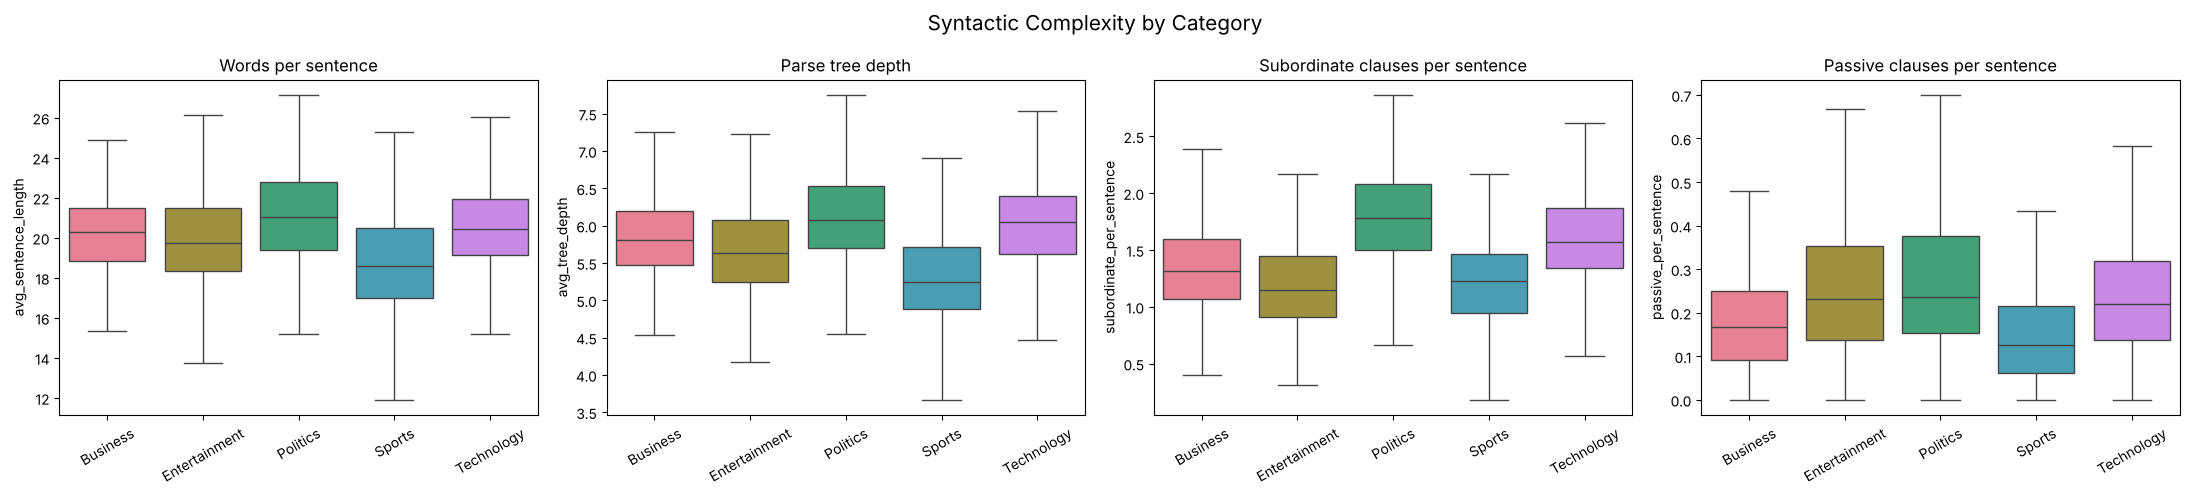

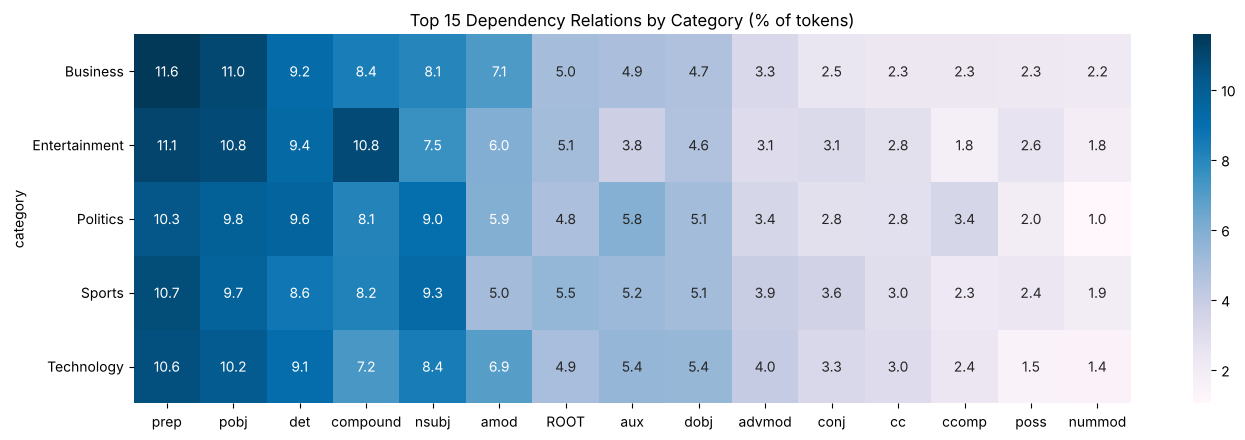

Business      over uses: nmod (x1.73), nummod (x1.31), case (x1.22)
Entertainment over uses: appos (x1.44), case (x1.30), compound (x1.27)
Politics      over uses: ccomp (x1.39), neg (x1.34), acl (x1.23)
Sports        over uses: npadvmod (x1.42), neg (x1.38), prt (x1.22)
Technology    over uses: relcl (x1.30), acl (x1.19), xcomp (x1.18)


In [17]:
# Compare syntactic complexity across categories
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, col, title in zip(axes,
        ['avg_sentence_length', 'avg_tree_depth', 'subordinate_per_sentence', 'passive_per_sentence'],
        ['Words per sentence', 'Parse tree depth', 'Subordinate clauses per sentence', 'Passive clauses per sentence']):
    sns.boxplot(data=syntax_df, x='category', y=col, order=CATEGORY_ORDER, palette=CAT_COLORS,
                showfliers=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
plt.suptitle('Syntactic Complexity by Category', fontsize=15)
plt.tight_layout()
plt.show()

# Most common dependency relations per category (normalized)
dep_rows = []
for r in syntactic_results:
    total = sum(r['dependency_counts'].values()) or 1
    row = {d: c / total for d, c in r['dependency_counts'].items()}
    row['category'] = r['category']
    dep_rows.append(row)
dep_df = pd.DataFrame(dep_rows).fillna(0)
dep_by_cat = dep_df.groupby('category').mean()
top_deps = dep_by_cat.mean().sort_values(ascending=False).head(15).index
plt.figure(figsize=(14, 4.5))
sns.heatmap(dep_by_cat[top_deps] * 100, annot=True, fmt='.1f', cmap='PuBu')
plt.title('Top 15 Dependency Relations by Category (% of tokens)')
plt.tight_layout()
plt.show()

# Relations that are relatively most over represented in each category
rel = dep_by_cat[top_deps.union(dep_by_cat.columns[dep_by_cat.mean() > 0.005])]
rel = rel / rel.mean()
for cat in CATEGORY_ORDER:
    top = rel.loc[cat].sort_values(ascending=False).head(3)
    print(f"{cat:13s} over uses: " + ', '.join(f"{d} (x{v:.2f})" for d, v in top.items()))

In [18]:
# Action patterns and semantic roles: who did what to whom
def extract_semantic_roles(doc):
    '''
    Simplified semantic role labeling from the dependency parse.
    For each main verb returns AGENT (active subject or passive "by" phrase), ACTION (verb lemma),
    PATIENT (direct object or passive subject), RECIPIENT (dative), LOCATION and TIME (from
    prepositional phrases containing GPE/LOC/FAC or DATE/TIME entities).
    '''
    def span_text(tok):
        # Use the compound / modifier subtree so "Verizon" stays "Verizon" but "the firm" keeps its noun
        words = [t for t in tok.subtree if t.dep_ in ('compound', 'amod', 'poss', 'nummod') or t == tok]
        return ' '.join(t.text for t in sorted(words, key=lambda t: t.i))

    frames = []
    for verb in doc:
        if verb.pos_ not in ('VERB',) or verb.dep_ in ('aux', 'auxpass', 'amod'):
            continue
        frame = {'AGENT': None, 'ACTION': verb.lemma_.lower(), 'PATIENT': None,
                 'RECIPIENT': None, 'LOCATION': None, 'TIME': None}
        for child in verb.children:
            if child.dep_ == 'nsubj':
                frame['AGENT'] = span_text(child)
            elif child.dep_ == 'nsubjpass':
                frame['PATIENT'] = span_text(child)
            elif child.dep_ == 'dobj':
                frame['PATIENT'] = span_text(child)
            elif child.dep_ == 'dative':
                frame['RECIPIENT'] = span_text(child)
            elif child.dep_ == 'agent':                     # passive "by" phrase
                pobj = [g for g in child.children if g.dep_ == 'pobj']
                if pobj:
                    frame['AGENT'] = span_text(pobj[0])
            elif child.dep_ == 'prep':
                for pobj in (g for g in child.children if g.dep_ == 'pobj'):
                    if pobj.ent_type_ in ('GPE', 'LOC', 'FAC'):
                        frame['LOCATION'] = f"{child.text} {span_text(pobj)}"
                    elif pobj.ent_type_ in ('DATE', 'TIME'):
                        frame['TIME'] = f"{child.text} {span_text(pobj)}"
        if frame['AGENT'] and frame['PATIENT']:
            frames.append(frame)
    return frames

role_rows = []
for doc, (_, row) in zip(docs, df.iterrows()):
    for frame in extract_semantic_roles(doc):
        frame.update({'article_id': row['article_id'], 'category': row['category']})
        role_rows.append(frame)
roles_df = pd.DataFrame(role_rows)
print(f"🎭 Extracted {len(roles_df):,} agent-action-patient frames "
      f"({len(roles_df) / len(df):.1f} per article)")

print("\n📋 Sample semantic role frames (one per category, with location or time when available):")
sample_frames = (roles_df[roles_df['LOCATION'].notna() | roles_df['TIME'].notna()]
                 .groupby('category').head(2))
print(sample_frames[['category', 'AGENT', 'ACTION', 'PATIENT', 'LOCATION', 'TIME']]
      .fillna('').to_string(index=False))

# Most frequent actions (verbs with both an agent and a patient) per category
print("\n⚡ TOP ACTIONS PER CATEGORY (lift over corpus rate, min 10 uses)")
action_counts = roles_df.groupby(['category', 'ACTION']).size().unstack(fill_value=0)
action_share = action_counts.div(action_counts.sum(axis=1), axis=0)
overall_share = action_counts.sum() / action_counts.values.sum()
action_lift = action_share / overall_share
for cat in CATEGORY_ORDER:
    eligible = action_counts.loc[cat][action_counts.loc[cat] >= 10].index
    top = action_lift.loc[cat, eligible].sort_values(ascending=False).head(8)
    print(f"  {cat:13s}: {', '.join(top.index)}")

🎭 Extracted 23,440 agent-action-patient frames (11.7 per article)

📋 Sample semantic role frames (one per category, with location or time when available):
     category                AGENT   ACTION                                            PATIENT LOCATION            TIME
     Politics            proposals increase                                              costs                  on year
     Politics                 they increase                                      maternity pay              in November
   Technology   US Customs Service    begin                      investigation other such 1911          In October 2000
     Business                   it    begin                                             trials                 in April
       Sports              Carroll     step                                           his form          in recent weeks
       Sports Kenya athletics body  suspend two time London Marathon runner up Susan Chepkemei                until end
   Te

### 📝 Syntax and Semantic Findings

* **Politics is the most syntactically complex** category: the longest sentences (21.2 words), the deepest parse trees and the most subordinate clauses (1.78 per sentence), with clausal complements (*ccomp*) over used by 39%. This is reported speech: "Mr Blair said that he would...".
* **Sports is the simplest:** the shortest sentences (18.7 words), shallowest trees and fewest passive clauses. Match reports are short, direct and active.
* **Technology** over uses relative clauses (*relcl*), again showing an explanatory style; **Business** over uses numeric modifiers (*nummod*); **Entertainment** over uses appositions (*appos*), as in "director Martin Scorsese".
* **Semantic roles:** we extracted 23,440 agent action patient frames (11.7 per article). The most characteristic actions are a compact summary of each beat: Sports *defeat, score, beat, kick*; Business *forecast, report, post, employ*; Technology *download, store, access, develop*; Entertainment *star, perform, direct, write*; Politics *propose, oppose, tackle, attack*.
* **Limitation:** the rule based role extractor sometimes returns pronouns (*it, they*) as agents or splits names (*Ferry Brian*). Coreference resolution would fix most of these.

## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

We measure sentiment with VADER at three levels (title, content, full article) and also average VADER over individual sentences. VADER's compound score was designed for short texts, so on a 400 word article it tends to saturate near +1 or minus 1; the **mean sentence compound** is a more stable article level measure and is the one we use for labels.

For **emotional tone** we use a transparent lexicon approach: counts of words linked to seven emotions (joy, trust, anticipation, surprise, fear, anger, sadness), matched on spaCy lemmas and normalized per 1,000 words.

**💡 Hypothesis:** Sports and entertainment are more positive, politics more negative.

In [19]:
# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()

def label_from_score(score, threshold=0.05):
    if score >= threshold:
        return 'positive'
    if score <= -threshold:
        return 'negative'
    return 'neutral'

def analyze_sentiment(text, doc=None):
    '''
    VADER sentiment for a text. Returns compound, pos, neu, neg, a label, plus sentence level
    statistics (mean compound across sentences, share of positive/negative sentences and volatility).
    '''
    if text is None or (isinstance(text, float) and pd.isna(text)) or not str(text).strip():
        return {'compound': 0, 'pos': 0, 'neu': 1, 'neg': 0, 'sentiment_label': 'neutral',
                'sent_mean': 0, 'sent_std': 0, 'pos_sent_share': 0, 'neg_sent_share': 0}
    scores = sia.polarity_scores(str(text))
    sentences = [s.text for s in doc.sents] if doc is not None else sent_tokenize(str(text))
    sent_scores = np.array([sia.polarity_scores(s)['compound'] for s in sentences]) if sentences else np.zeros(1)
    scores['sent_mean'] = float(sent_scores.mean())
    scores['sent_std'] = float(sent_scores.std())
    scores['pos_sent_share'] = float((sent_scores >= 0.05).mean())
    scores['neg_sent_share'] = float((sent_scores <= -0.05).mean())
    scores['sentiment_label'] = label_from_score(scores['sent_mean'])
    return scores

print("😊 Analyzing sentiment...")
start = time.time()
sentiment_results = []
for doc, (_, row) in zip(docs, df.iterrows()):
    title_s = sia.polarity_scores(row['title'])['compound']
    content_s = sia.polarity_scores(row['content'])['compound']
    full = analyze_sentiment(row['full_text'], doc=doc)
    sentiment_results.append({
        'article_id': row['article_id'], 'category': row['category'],
        'title_sentiment': title_s, 'title_label': label_from_score(title_s),
        'content_sentiment': content_s, 'content_label': label_from_score(content_s),
        'full_sentiment': full['compound'], 'full_label': label_from_score(full['compound']),
        'sent_mean': full['sent_mean'], 'article_label': full['sentiment_label'],
        'sent_std': full['sent_std'], 'pos_sent_share': full['pos_sent_share'],
        'neg_sent_share': full['neg_sent_share'],
        'pos_score': full['pos'], 'neu_score': full['neu'], 'neg_score': full['neg'],
    })
sentiment_df = pd.DataFrame(sentiment_results)
print(f"✅ Sentiment analysis complete in {time.time() - start:.1f}s! Analyzed {len(sentiment_df)} articles")

print(f"\n⚠️ Saturation check: {(sentiment_df['full_sentiment'].abs() > 0.9).mean():.0%} of whole article "
      f"compound scores are beyond ±0.9, versus {(sentiment_df['sent_mean'].abs() > 0.9).mean():.0%} for the sentence mean.")
print("\n📝 Sample sentiment results:")
print(sentiment_df[['category', 'title_sentiment', 'full_sentiment', 'sent_mean', 'article_label']].head().round(3))

😊 Analyzing sentiment...


✅ Sentiment analysis complete in 19.4s! Analyzed 2000 articles

⚠️ Saturation check: 69% of whole article compound scores are beyond ±0.9, versus 0% for the sentence mean.

📝 Sample sentiment results:
     category  title_sentiment  full_sentiment  sent_mean article_label
0    Politics            0.000           0.997      0.297      positive
1  Technology            0.178           0.993      0.091      positive
2      Sports            0.572           0.982      0.402      positive
3    Business            0.000           0.950      0.178      positive
4    Business            0.000           0.991      0.234      positive


📊 SENTIMENT ANALYSIS BY CATEGORY

📈 Sentiment statistics by category (sent_mean = article level score):
              sent_mean                         full_sentiment  \
                   mean     std     min     max           mean   
category                                                         
Business         0.0476  0.1690 -0.4622  0.5140         0.2236   
Entertainment    0.1756  0.2275 -0.4574  0.7538         0.5811   
Politics         0.0107  0.1566 -0.5679  0.5934         0.0738   
Sports           0.1270  0.1854 -0.5746  0.7771         0.5562   
Technology       0.0958  0.1489 -0.4428  0.7930         0.5425   

              title_sentiment pos_score neu_score neg_score sent_std  
                         mean      mean      mean      mean     mean  
category                                                              
Business               0.0061    0.0895    0.8420    0.0685   0.3450  
Entertainment          0.1073    0.1306    0.8172    0.0522   0.3637  
Politics    

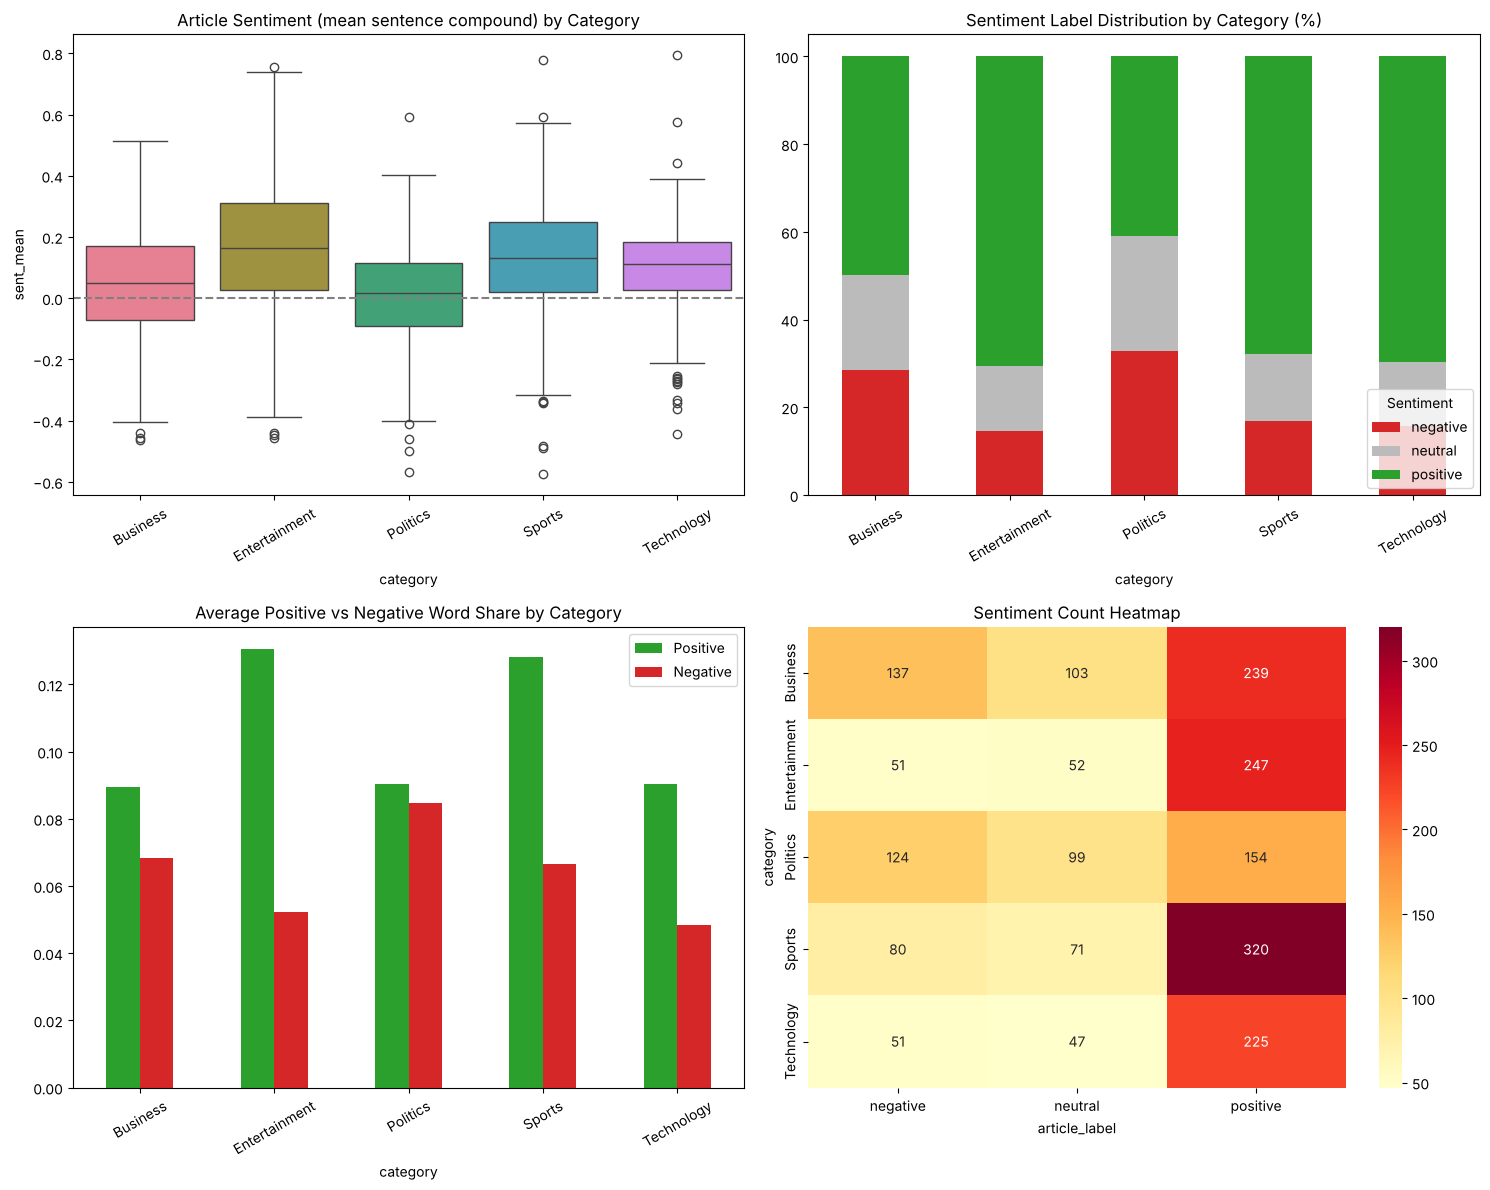

In [20]:
# Analyze sentiment patterns by category
print("📊 SENTIMENT ANALYSIS BY CATEGORY")
print("=" * 50)
sentiment_by_category = sentiment_df.groupby('category').agg({
    'sent_mean': ['mean', 'std', 'min', 'max'],
    'full_sentiment': 'mean',
    'title_sentiment': 'mean',
    'pos_score': 'mean', 'neu_score': 'mean', 'neg_score': 'mean',
    'sent_std': 'mean'
}).round(4)
print("\n📈 Sentiment statistics by category (sent_mean = article level score):")
print(sentiment_by_category)

sentiment_dist = sentiment_df.groupby(['category', 'article_label']).size().unstack(fill_value=0)
sentiment_dist = sentiment_dist[[c for c in ['negative', 'neutral', 'positive'] if c in sentiment_dist]]
sentiment_dist_pct = sentiment_dist.div(sentiment_dist.sum(axis=1), axis=0) * 100
print("\n📊 Sentiment distribution (%) by category:")
print(sentiment_dist_pct.round(1))

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
sns.boxplot(data=sentiment_df, x='category', y='sent_mean', order=CATEGORY_ORDER,
            palette=CAT_COLORS, ax=axes[0, 0])
axes[0, 0].axhline(0, color='grey', ls='--')
axes[0, 0].set_title('Article Sentiment (mean sentence compound) by Category')
axes[0, 0].tick_params(axis='x', rotation=30)

sentiment_dist_pct.plot(kind='bar', ax=axes[0, 1], stacked=True, color=['#d62728', '#bbbbbb', '#2ca02c'])
axes[0, 1].set_title('Sentiment Label Distribution by Category (%)')
axes[0, 1].tick_params(axis='x', rotation=30)
axes[0, 1].legend(title='Sentiment', loc='lower right')

category_means = sentiment_df.groupby('category')[['pos_score', 'neg_score']].mean()
category_means.plot(kind='bar', ax=axes[1, 0], color=['#2ca02c', '#d62728'])
axes[1, 0].set_title('Average Positive vs Negative Word Share by Category')
axes[1, 0].tick_params(axis='x', rotation=30)
axes[1, 0].legend(['Positive', 'Negative'])

sentiment_pivot = sentiment_df.pivot_table(values='sent_mean', index='category',
                                           columns='article_label', aggfunc='count', fill_value=0)
sns.heatmap(sentiment_pivot, annot=True, fmt='d', ax=axes[1, 1], cmap='YlOrRd')
axes[1, 1].set_title('Sentiment Count Heatmap')
plt.tight_layout()
plt.show()

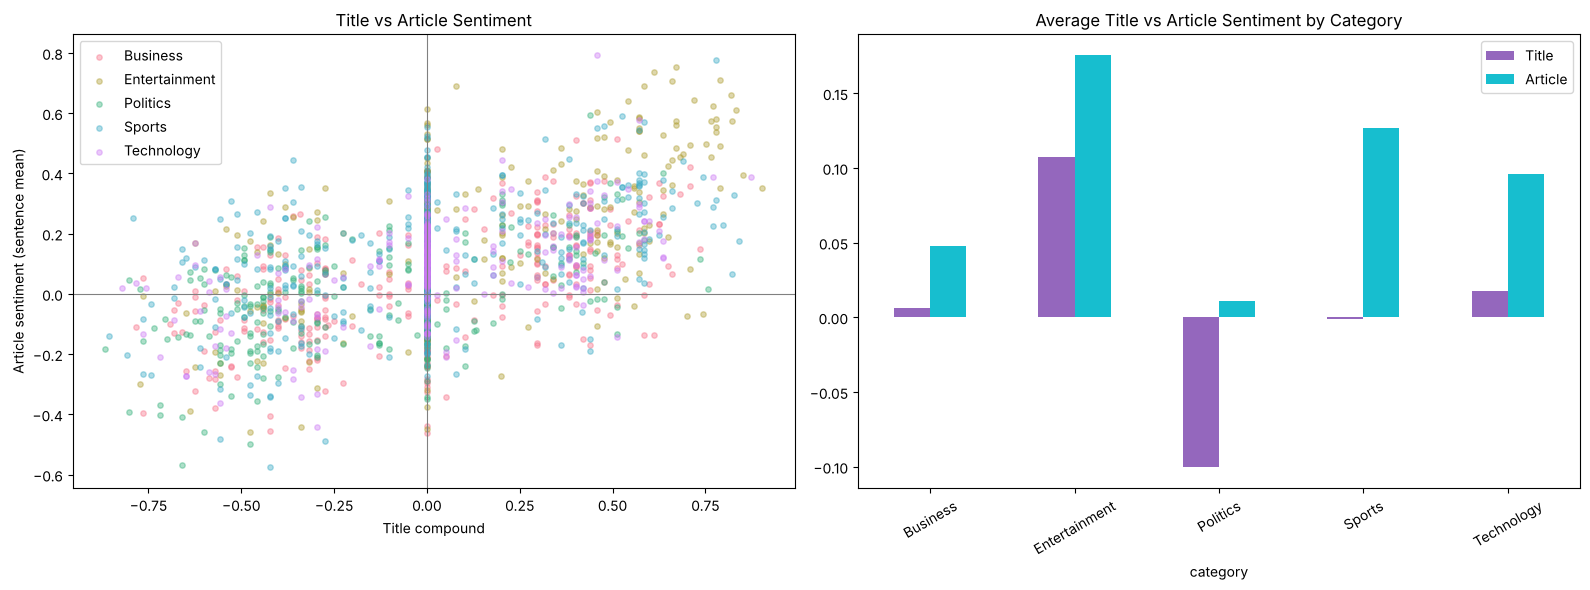

📰 49% of headlines are neutral (no sentiment words); title vs article correlation r = 0.51
📏 Within category spread (std of article sentiment): Business 0.169, Entertainment 0.227, Politics 0.157, Sports 0.185, Technology 0.149
🤖 Sentiment features alone classify categories with 36.1% accuracy (chance = 23.9%)


In [21]:
# Title vs content sentiment, and within category variation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for cat in CATEGORY_ORDER:
    sub = sentiment_df[sentiment_df['category'] == cat]
    axes[0].scatter(sub['title_sentiment'], sub['sent_mean'], alpha=0.4, s=15, label=cat, color=CAT_COLORS[cat])
axes[0].axhline(0, color='grey', lw=0.8); axes[0].axvline(0, color='grey', lw=0.8)
axes[0].set_xlabel('Title compound'); axes[0].set_ylabel('Article sentiment (sentence mean)')
axes[0].set_title('Title vs Article Sentiment')
axes[0].legend()

title_vs = sentiment_df.groupby('category')[['title_sentiment', 'sent_mean']].mean()
title_vs.plot(kind='bar', ax=axes[1], color=['#9467bd', '#17becf'])
axes[1].set_title('Average Title vs Article Sentiment by Category')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(['Title', 'Article'])
plt.tight_layout()
plt.show()

neutral_titles = (sentiment_df['title_label'] == 'neutral').mean()
corr = sentiment_df[['title_sentiment', 'sent_mean']].corr().iloc[0, 1]
print(f"📰 {neutral_titles:.0%} of headlines are neutral (no sentiment words); "
      f"title vs article correlation r = {corr:.2f}")
print(f"📏 Within category spread (std of article sentiment): "
      + ', '.join(f"{c} {s:.3f}" for c, s in sentiment_df.groupby('category')['sent_mean'].std().items()))

# Can sentiment alone predict the category?
sent_only = cross_val_score(LogisticRegression(max_iter=2000),
                            sentiment_df[['sent_mean', 'full_sentiment', 'pos_score', 'neg_score', 'neu_score', 'sent_std']],
                            sentiment_df['category'], cv=cv5)
print(f"🤖 Sentiment features alone classify categories with {sent_only.mean():.1%} accuracy "
      f"(chance = {df['category'].value_counts(normalize=True).max():.1%})")

🎭 EMOTION WORDS PER 1,000 WORDS BY CATEGORY
                 joy  trust  anticipation  surprise  fear  anger  sadness
category                                                                 
Business        3.24   4.59          7.33      0.30  2.85   2.02     3.96
Entertainment  15.86   1.86          2.96      0.56  0.97   1.88     2.93
Politics        2.62   4.47          7.76      0.23  4.00   3.26     2.41
Sports         10.95   2.55          4.23      0.68  1.30   3.07     7.12
Technology      2.80   2.27          5.72      0.23  3.68   1.61     1.14

Dominant emotion share by category (%):
dominant_emotion  anger  anticipation  fear   joy  sadness  surprise  trust
category                                                                   
Business            5.2          37.6   6.5  17.1     10.9       0.2   22.5
Entertainment       5.4           6.9   2.3  71.4      8.3       0.6    5.1
Politics            8.0          40.6  12.2  11.7      5.6       0.3   21.8
Sports           

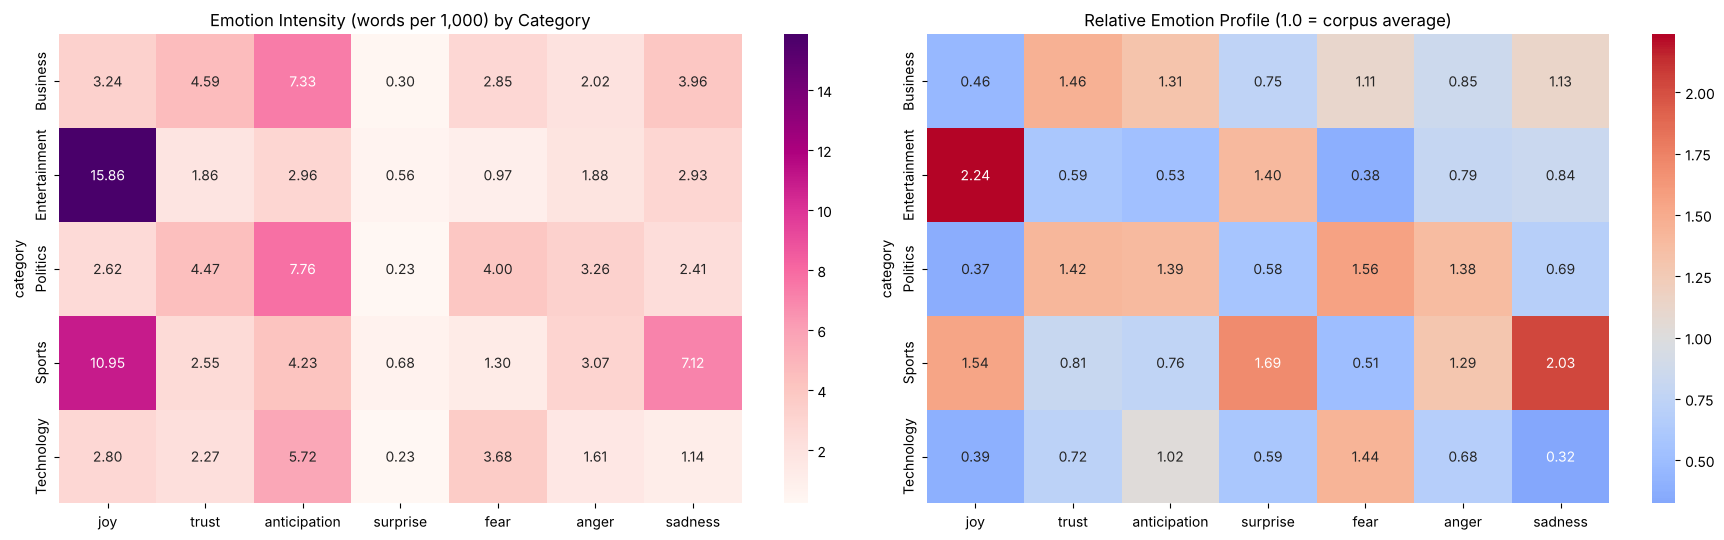

In [22]:
# Emotional tone analysis with an emotion lexicon (matched on spaCy lemmas)
EMOTION_LEXICON = {
    'joy':          {'win', 'celebrate', 'happy', 'delight', 'delighted', 'success', 'successful', 'triumph',
                     'love', 'enjoy', 'glory', 'award', 'praise', 'cheer', 'pleased', 'thrill', 'victory',
                     'fun', 'laugh', 'proud', 'best', 'great', 'star', 'hit', 'excellent', 'boost'},
    'trust':        {'agree', 'agreement', 'support', 'confidence', 'confident', 'reliable', 'trust', 'secure',
                     'promise', 'ally', 'partner', 'partnership', 'endorse', 'loyal', 'faith', 'honest',
                     'stable', 'guarantee', 'commit', 'commitment', 'deal', 'protect'},
    'anticipation': {'expect', 'plan', 'future', 'forecast', 'upcoming', 'prepare', 'launch', 'soon', 'await',
                     'predict', 'hope', 'aim', 'target', 'next', 'prospect', 'intend', 'propose', 'schedule'},
    'surprise':     {'surprise', 'shock', 'unexpected', 'sudden', 'suddenly', 'stun', 'stunning', 'astonish',
                     'remarkable', 'dramatic', 'unprecedented', 'shocking', 'amazing', 'upset'},
    'fear':         {'fear', 'threat', 'threaten', 'risk', 'warn', 'warning', 'danger', 'dangerous', 'crisis',
                     'worry', 'concern', 'terror', 'terrorism', 'panic', 'alarm', 'uncertainty', 'vulnerable',
                     'scare', 'afraid', 'anxiety', 'virus', 'attack'},
    'anger':        {'anger', 'angry', 'row', 'fury', 'furious', 'outrage', 'protest', 'criticise', 'criticize',
                     'criticism', 'condemn', 'accuse', 'blame', 'clash', 'dispute', 'hostile', 'slam', 'rage',
                     'fight', 'attack', 'ban', 'sue', 'lawsuit'},
    'sadness':      {'loss', 'lose', 'death', 'die', 'decline', 'injury', 'injure', 'sad', 'tragic', 'mourn',
                     'fail', 'failure', 'defeat', 'unemployment', 'poor', 'suffer', 'miss', 'collapse',
                     'struggle', 'disappointing', 'disappoint', 'grief'},
}
EMOTIONS = list(EMOTION_LEXICON)

def emotion_profile(doc):
    '''Emotion word counts per 1,000 words for a parsed spaCy doc.'''
    lemmas = [t.lemma_.lower() for t in doc if t.is_alpha]
    n = max(len(lemmas), 1)
    counts = Counter(lemmas)
    return {emo: 1000 * sum(counts[w] for w in words) / n for emo, words in EMOTION_LEXICON.items()}

emotion_df = pd.DataFrame([emotion_profile(d) for d in docs])
emotion_df['category'] = df['category'].values
emotion_df['dominant_emotion'] = emotion_df[EMOTIONS].idxmax(axis=1)
emotion_by_cat = emotion_df.groupby('category')[EMOTIONS].mean()

print("🎭 EMOTION WORDS PER 1,000 WORDS BY CATEGORY")
print(emotion_by_cat.round(2))
print("\nDominant emotion share by category (%):")
print((pd.crosstab(emotion_df['category'], emotion_df['dominant_emotion'], normalize='index') * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
sns.heatmap(emotion_by_cat, annot=True, fmt='.2f', cmap='RdPu', ax=axes[0])
axes[0].set_title('Emotion Intensity (words per 1,000) by Category')
# Relative profile: how each category deviates from the corpus average
rel_emotion = emotion_by_cat / emotion_by_cat.mean()
sns.heatmap(rel_emotion, annot=True, fmt='.2f', cmap='coolwarm', center=1, ax=axes[1])
axes[1].set_title('Relative Emotion Profile (1.0 = corpus average)')
plt.tight_layout()
plt.show()

### 📝 Sentiment and Emotion Findings

* **Measurement matters.** 69% of whole article VADER compound scores are saturated beyond ±0.9, which makes them almost useless for comparing articles. The mean sentence score has no saturation, so we use it as the article level score.
* **Most positive:** Entertainment (mean 0.176, 71% positive articles), followed by Sports and Technology. **Most negative:** Politics (mean 0.011, 33% negative articles) and Business (29% negative). This supports the hypothesis that sports and entertainment are more positive and politics more negative.
* **Headlines vs body:** about half of all headlines contain no sentiment words at all, and headline and body sentiment correlate only moderately (r = 0.51). Political headlines are the most negative of all (mean minus 0.10) even though the body text is roughly neutral, which suggests negative framing in headlines.
* **Within category variation** is large (standard deviation 0.15 to 0.23), largest in Entertainment, where glowing reviews sit next to obituaries and court cases.
* **Sentiment as a classifier feature:** sentiment alone predicts the category with 36% accuracy, better than the 24% baseline but far weaker than vocabulary.
* **Emotional tone:** Entertainment is dominated by **joy** (15.9 joy words per 1,000, 71% of articles), Politics and Technology by **fear** and **anticipation** (risks, warnings, plans), and Business by **trust** and anticipation (deals, forecasts). Sports scores high on both joy and *sadness*, but the sadness is largely a lexicon artifact: *miss*, *defeat* and *injury* are routine sports vocabulary. This is a good reminder that general purpose lexicons need domain checking.

## 🏷️ Text Classification System

### 🎯 Module 7: Building the News Classifier

The core of NewsBot is a multi class classifier.

**Classification Pipeline:**
1. **Feature Engineering:** TF-IDF features plus engineered linguistic features (sentiment, length, POS mix, syntax complexity, entity density) from Modules 4 to 8
2. **Model Training:** four algorithms (Naive Bayes, Logistic Regression, linear SVM, Random Forest)
3. **Model Evaluation:** 5 fold cross validation on the training set, then a held out test set
4. **Optimization:** grid search over TF-IDF and model hyperparameters, plus chi squared feature selection
5. **Model Selection:** the best model becomes the NewsBot engine

**Design note.** Every transformation lives inside a scikit-learn Pipeline, so the TF-IDF vocabulary and scalers are fit only on training folds. This avoids data leakage, and the exact same pipeline is reused for new articles in the final system (no dummy features).

**💡 Business Impact:** accurate classification enables automatic content routing, personalized recommendations and efficient content management.

In [23]:
# Engineered linguistic features, computed by ONE function for both training data and new articles
ENTITY_TYPES = ['PERSON', 'ORG', 'GPE', 'DATE', 'MONEY', 'PERCENT', 'CARDINAL', 'NORP']

def compute_meta_features(title, full_text, doc):
    '''
    Linguistic features for one article (title, title + content text, parsed spaCy doc).
    Sentiment (Module 6), length, POS mix (Module 4, spaCy universal tags), syntactic complexity
    (Module 5) and entity density (Module 8).
    '''
    words = [t for t in doc if not t.is_punct and not t.is_space]
    n = max(len(words), 1)
    sents = list(doc.sents)
    n_sent = max(len(sents), 1)
    vs = sia.polarity_scores(full_text)
    sent_scores = [sia.polarity_scores(s.text)['compound'] for s in sents] or [0]
    pos_counts = Counter(t.pos_ for t in words)
    ent_counts = Counter(e.label_ for e in doc.ents)
    feats = {
        'sent_compound': vs['compound'], 'sent_mean': float(np.mean(sent_scores)),
        'sent_pos': vs['pos'], 'sent_neg': vs['neg'], 'sent_neu': vs['neu'],
        'char_length': len(full_text), 'word_count': n, 'title_length': len(str(title).split()),
        'avg_sentence_length': n / n_sent,
        'subordinate_per_sentence': sum(t.dep_ in SUBORDINATE_DEPS for t in doc) / n_sent,
        'passive_per_sentence': sum(t.dep_ == 'nsubjpass' for t in doc) / n_sent,
    }
    for p in ['NOUN', 'PROPN', 'VERB', 'ADJ', 'ADV', 'NUM', 'PRON']:
        feats[f'pos_{p}'] = pos_counts[p] / n
    for e in ENTITY_TYPES:
        feats[f'ent_{e}'] = 100 * ent_counts[e] / n
    return feats

print("🔧 Preparing features for classification...")
meta_df = pd.DataFrame([compute_meta_features(t, ft, d)
                        for t, ft, d in zip(df['title'], df['full_text'], docs)])
META_COLS = list(meta_df.columns)

model_df = pd.concat([df[['full_text_processed']].reset_index(drop=True), meta_df], axis=1)
y = df['category'].values

X_train, X_test = model_df.loc[train_idx], model_df.loc[test_idx]
y_train, y_test = df.loc[train_idx, 'category'].values, df.loc[test_idx, 'category'].values

print(f"✅ Feature table prepared: {model_df.shape[0]} articles, 1 text column + {len(META_COLS)} engineered features")
print(f"🎯 Number of classes: {len(np.unique(y))}  📋 Classes: {np.unique(y)}")
print(f"\n📈 Data split (same stratified split used in Module 3):")
print(f"  Training set: {len(X_train)} samples")
print(f"  Test set: {len(X_test)} samples")
print("\nEngineered feature means by category (selected):")
print(pd.concat([meta_df, df['category']], axis=1).groupby('category')[
    ['sent_mean', 'word_count', 'pos_PROPN', 'pos_NUM', 'ent_MONEY', 'ent_PERSON']].mean().round(3))

🔧 Preparing features for classification...


✅ Feature table prepared: 2000 articles, 1 text column + 26 engineered features
🎯 Number of classes: 5  📋 Classes: ['Business' 'Entertainment' 'Politics' 'Sports' 'Technology']

📈 Data split (same stratified split used in Module 3):
  Training set: 1600 samples
  Test set: 400 samples

Engineered feature means by category (selected):
               sent_mean  word_count  pos_PROPN  pos_NUM  ent_MONEY  \
category                                                              
Business           0.048     340.478      0.110    0.038      0.890   
Entertainment      0.176     345.774      0.163    0.032      0.457   
Politics           0.011     469.329      0.116    0.017      0.196   
Sports             0.127     339.064      0.161    0.031      0.050   
Technology         0.096     528.015      0.081    0.022      0.189   

               ent_PERSON  
category                   
Business            1.391  
Entertainment       3.832  
Politics            2.420  
Sports              4.266 

🤖 Training multiple classifiers...


  Naive Bayes | TF-IDF only                  CV acc 0.9781 (+/- 0.0105) | test acc 0.9575 | 5s


  Logistic Regression | TF-IDF only          CV acc 0.9819 (+/- 0.0183) | test acc 0.9700 | 7s


  SVM | TF-IDF only                          CV acc 0.9825 (+/- 0.0188) | test acc 0.9675 | 18s


  Random Forest | TF-IDF only                CV acc 0.9587 (+/- 0.0183) | test acc 0.9450 | 16s


  Naive Bayes | TF-IDF + linguistic          CV acc 0.9756 (+/- 0.0133) | test acc 0.9600 | 5s


  Logistic Regression | TF-IDF + linguistic  CV acc 0.9650 (+/- 0.0155) | test acc 0.9600 | 9s


  SVM | TF-IDF + linguistic                  CV acc 0.9719 (+/- 0.0105) | test acc 0.9600 | 14s


  Random Forest | TF-IDF + linguistic        CV acc 0.9606 (+/- 0.0109) | test acc 0.9525 | 17s

🏆 CLASSIFIER COMPARISON
              Model            Features  CV Mean  CV Std  CV Macro F1  Test Accuracy  Test Macro F1
                SVM         TF-IDF only   0.9825  0.0094       0.9820         0.9675         0.9671
Logistic Regression         TF-IDF only   0.9819  0.0091       0.9815         0.9700         0.9698
        Naive Bayes         TF-IDF only   0.9781  0.0052       0.9771         0.9575         0.9571
        Naive Bayes TF-IDF + linguistic   0.9756  0.0067       0.9744         0.9600         0.9594
                SVM TF-IDF + linguistic   0.9719  0.0052       0.9706         0.9600         0.9586
Logistic Regression TF-IDF + linguistic   0.9650  0.0078       0.9637         0.9600         0.9595
      Random Forest TF-IDF + linguistic   0.9606  0.0054       0.9598         0.9525         0.9524
      Random Forest         TF-IDF only   0.9588  0.0091       0.9572         0

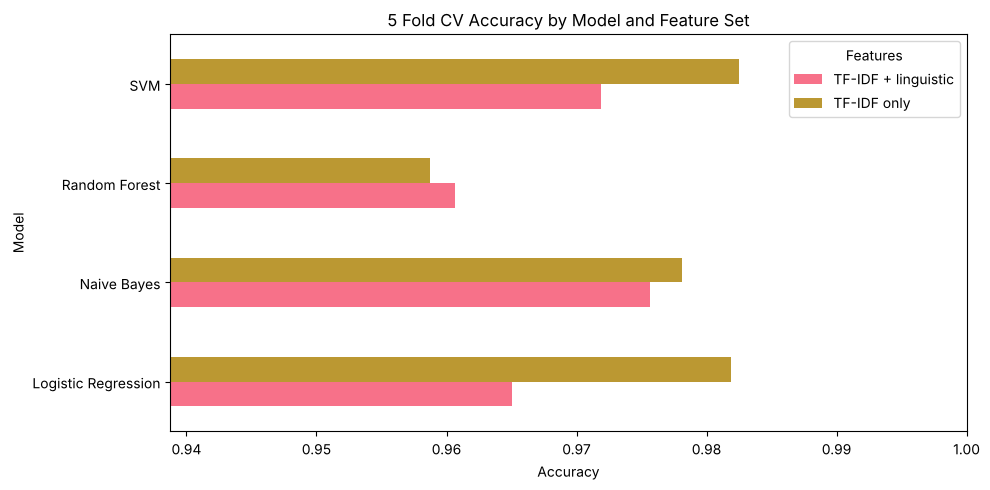

In [24]:
# Train and evaluate multiple classifiers on two feature sets
print("🤖 Training multiple classifiers...")

def make_features(use_meta):
    # TF-IDF on processed text, optionally plus min max scaled engineered features
    # (MinMaxScaler with clip keeps values non negative, which Multinomial Naive Bayes requires)
    transformers = [('tfidf', TfidfVectorizer(**BEST_TFIDF_PARAMS), 'full_text_processed')]
    if use_meta:
        transformers.append(('meta', MinMaxScaler(clip=True), META_COLS))
    return ColumnTransformer(transformers)

classifiers = {
    'Naive Bayes': MultinomialNB(alpha=0.1),
    'Logistic Regression': LogisticRegression(random_state=RANDOM_STATE, max_iter=2000, C=10),
    # probability=False while comparing (5x faster); the final model is refit with probability=True
    'SVM': SVC(kernel='linear', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}
feature_sets = {'TF-IDF only': False, 'TF-IDF + linguistic': True}

results, trained_models = {}, {}
for fs_name, use_meta in feature_sets.items():
    for name, classifier in classifiers.items():
        key = f"{name} | {fs_name}"
        pipe = Pipeline([('features', make_features(use_meta)), ('clf', classifier)])
        t0 = time.time()
        cv = cross_validate(pipe, X_train, y_train, cv=cv5, scoring=['accuracy', 'f1_macro'], n_jobs=-1)
        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)
        results[key] = {
            'model': name, 'features': fs_name,
            'cv_mean': cv['test_accuracy'].mean(), 'cv_std': cv['test_accuracy'].std(),
            'cv_f1': cv['test_f1_macro'].mean(),
            'accuracy': accuracy_score(y_test, y_pred),
            'f1_macro': f1_score(y_test, y_pred, average='macro'),
            'predictions': y_pred,
            'train_time': time.time() - t0,
        }
        trained_models[key] = pipe
        print(f"  {key:42s} CV acc {cv['test_accuracy'].mean():.4f} (+/- {cv['test_accuracy'].std() * 2:.4f}) "
              f"| test acc {results[key]['accuracy']:.4f} | {results[key]['train_time']:.0f}s")

print("\n🏆 CLASSIFIER COMPARISON")
print("=" * 50)
comparison_df = pd.DataFrame([{
    'Model': r['model'], 'Features': r['features'], 'CV Mean': r['cv_mean'], 'CV Std': r['cv_std'],
    'CV Macro F1': r['cv_f1'], 'Test Accuracy': r['accuracy'], 'Test Macro F1': r['f1_macro']}
    for r in results.values()]).sort_values('CV Mean', ascending=False)
print(comparison_df.round(4).to_string(index=False))

# Select the best model by cross validation (not by test score, which would overfit the test set)
best_row = comparison_df.iloc[0]
best_model_name = f"{best_row['Model']} | {best_row['Features']}"
print(f"\n🥇 Best performing model (by CV): {best_model_name}")

pivot = comparison_df.pivot(index='Model', columns='Features', values='CV Mean')
pivot.plot(kind='barh', figsize=(10, 5), xlim=(max(0.85, pivot.values.min() - 0.02), 1.0))
plt.title('5 Fold CV Accuracy by Model and Feature Set')
plt.xlabel('Accuracy')
plt.tight_layout()
plt.show()

In [25]:
# Performance optimization 1: grid search over TF-IDF and model hyperparameters for the best family
best_family = best_row['Model']
use_meta = best_row['Features'] == 'TF-IDF + linguistic'
print(f"🔍 Grid search for {best_family} ({best_row['Features']})")

param_grids = {
    'Logistic Regression': {'clf__C': [1, 10, 50]},
    'SVM': {'clf__C': [0.5, 1, 5]},
    'Naive Bayes': {'clf__alpha': [0.01, 0.05, 0.1, 0.5]},
    'Random Forest': {'clf__max_features': ['sqrt', 'log2']},
}
grid = {
    'features__tfidf__max_features': [5000, 15000],
    'features__tfidf__sublinear_tf': [True, False],
    **param_grids[best_family],
}
search = GridSearchCV(Pipeline([('features', make_features(use_meta)),
                                ('clf', classifiers[best_family])]),
                      grid, cv=cv5, scoring='accuracy', n_jobs=-1)
t0 = time.time()
search.fit(X_train, y_train)
print(f"Tried {len(search.cv_results_['params'])} combinations in {time.time() - t0:.0f}s")
print(f"Best params: {search.best_params_}")
print(f"Best CV accuracy: {search.best_score_:.4f} (untuned: {best_row['CV Mean']:.4f})")
tuned_test_acc = accuracy_score(y_test, search.predict(X_test))
print(f"Tuned model test accuracy: {tuned_test_acc:.4f}")

# Keep the tuned model if it improves cross validation accuracy
if search.best_score_ > best_row['CV Mean']:
    tuned_key = f"{best_family} (tuned) | {best_row['Features']}"
    trained_models[tuned_key] = search.best_estimator_
    y_pred = search.predict(X_test)
    results[tuned_key] = {'model': f"{best_family} (tuned)", 'features': best_row['Features'],
                          'cv_mean': search.best_score_, 'accuracy': tuned_test_acc,
                          'f1_macro': f1_score(y_test, y_pred, average='macro'), 'predictions': y_pred}
    best_model_name = tuned_key
print(f"\n🥇 Final model: {best_model_name}")

🔍 Grid search for SVM (TF-IDF only)


Tried 12 combinations in 124s
Best params: {'clf__C': 1, 'features__tfidf__max_features': 15000, 'features__tfidf__sublinear_tf': True}
Best CV accuracy: 0.9831 (untuned: 0.9825)


Tuned model test accuracy: 0.9675



🥇 Final model: SVM (tuned) | TF-IDF only


✂️ FEATURE SELECTION: keeping only the top k TF-IDF terms by chi squared


k features  CV accuracy
       250       0.9644
       500       0.9706
      1000       0.9750
      2500       0.9762
       all       0.9819



⚖️ Macro F1 with balanced class weights: 0.9807 vs default: 0.9815


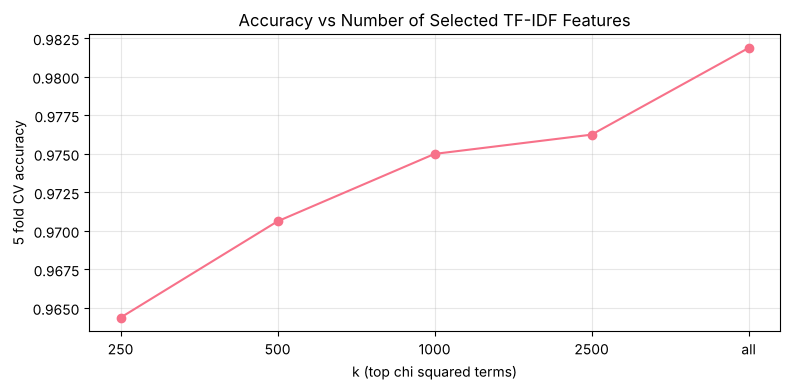

In [26]:
# Performance optimization 2: chi squared feature selection on TF-IDF features
print("✂️ FEATURE SELECTION: keeping only the top k TF-IDF terms by chi squared")
fs_rows = []
for k in [250, 500, 1000, 2500, 'all']:
    pipe = Pipeline([('tfidf', TfidfVectorizer(**BEST_TFIDF_PARAMS)),
                     ('select', SelectKBest(chi2, k=k)),
                     ('clf', LogisticRegression(max_iter=2000, C=10))])
    s = cross_val_score(pipe, X_train['full_text_processed'], y_train, cv=cv5, n_jobs=-1)
    fs_rows.append({'k features': str(k), 'CV accuracy': s.mean()})
fs_df = pd.DataFrame(fs_rows)
print(fs_df.round(4).to_string(index=False))

# Class imbalance check: does class_weight='balanced' help?
bal = cross_val_score(Pipeline([('tfidf', TfidfVectorizer(**BEST_TFIDF_PARAMS)),
                                ('clf', LogisticRegression(max_iter=2000, C=10, class_weight='balanced'))]),
                      X_train['full_text_processed'], y_train, cv=cv5, scoring='f1_macro', n_jobs=-1)
unbal = cross_val_score(Pipeline([('tfidf', TfidfVectorizer(**BEST_TFIDF_PARAMS)),
                                  ('clf', LogisticRegression(max_iter=2000, C=10))]),
                        X_train['full_text_processed'], y_train, cv=cv5, scoring='f1_macro', n_jobs=-1)
print(f"\n⚖️ Macro F1 with balanced class weights: {bal.mean():.4f} vs default: {unbal.mean():.4f}")

plt.figure(figsize=(8, 4))
plt.plot(fs_df['k features'], fs_df['CV accuracy'], marker='o')
plt.title('Accuracy vs Number of Selected TF-IDF Features')
plt.xlabel('k (top chi squared terms)'); plt.ylabel('5 fold CV accuracy')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

📊 DETAILED EVALUATION: SVM (tuned) | TF-IDF only
Test accuracy: 0.9675

📋 Classification Report:
               precision    recall  f1-score   support

     Business     0.9490    0.9688    0.9588        96
Entertainment     0.9577    0.9714    0.9645        70
     Politics     0.9589    0.9333    0.9459        75
       Sports     1.0000    0.9787    0.9892        94
   Technology     0.9697    0.9846    0.9771        65

     accuracy                         0.9675       400
    macro avg     0.9671    0.9674    0.9671       400
 weighted avg     0.9677    0.9675    0.9675       400



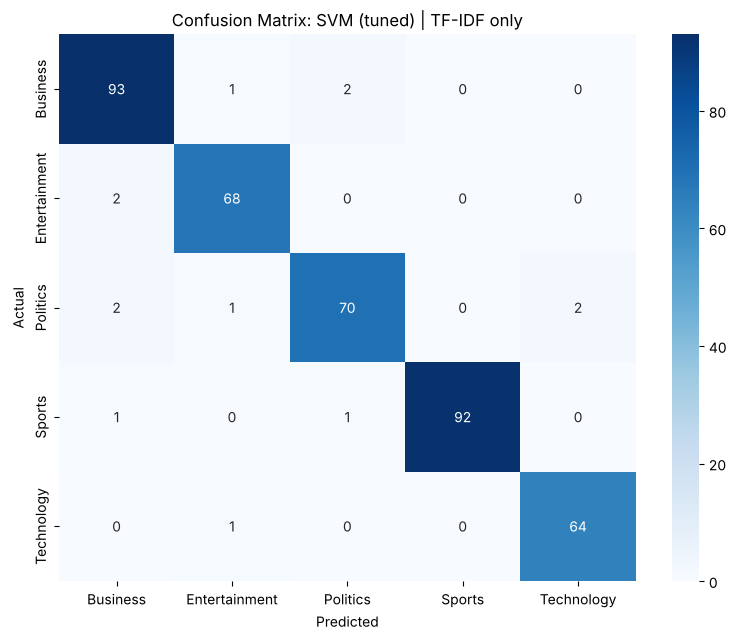


❌ Misclassified test articles (13 of 400):
                                  title       category      predicted
1695  MPs issued with Blackberry threat       Politics     Technology
340     Report attacks defence spending       Politics       Business
738    Golden rule boost for Chancellor       Business       Politics
1766    Parents face video game lessons     Technology  Entertainment
29      Campbell to be Lions consultant         Sports       Politics
1573     McDonald's to sponsor MTV show       Business  Entertainment
41      Game warnings 'must be clearer'       Politics  Entertainment
1828  Wal-Mart is sued over rude lyrics  Entertainment       Business
1115  Ferdinand casts doubt over Glazer         Sports       Business
951   UK's National Gallery in the pink  Entertainment       Business
852          Salary scandal in Cameroon       Business       Politics
283            EU fraud clampdown urged       Politics       Business
1313    UK firms 'embracing e-commerce'       

In [27]:
# Detailed evaluation of the best model on the held out test set
best_model = trained_models[best_model_name]
# NewsBot needs class probabilities; an SVM is refit once with Platt scaling (probability=True)
if not hasattr(best_model, 'predict_proba'):
    best_model = clone(best_model).set_params(clf__probability=True).fit(X_train, y_train)
    trained_models[best_model_name] = best_model
best_predictions = results[best_model_name]['predictions']

print(f"📊 DETAILED EVALUATION: {best_model_name}")
print("=" * 60)
print(f"Test accuracy: {accuracy_score(y_test, best_predictions):.4f}")
print("\n📋 Classification Report:")
print(classification_report(y_test, best_predictions, digits=4))

labels = np.unique(y)
cm = confusion_matrix(y_test, best_predictions, labels=labels)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title(f'Confusion Matrix: {best_model_name}')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# Misclassified articles: what does the model get wrong?
test_view = df.loc[test_idx, ['title', 'category']].copy()
test_view['predicted'] = best_predictions
errors = test_view[test_view['category'] != test_view['predicted']]
print(f"\n❌ Misclassified test articles ({len(errors)} of {len(test_view)}):")
print(errors.to_string())

🔍 Top Features by Category (Logistic Regression coefficients):
  📰 Business: firm, company, bank, economic, market, share, rise, economy, analyst, financial
  📰 Entertainment: film, star, music, band, show, album, singer, award, actor, song
  📰 Politics: party, minister, labour, tory, blair, government, secretary, committee, election, police
  📰 Sports: match, club, coach, player, win, cup, team, champion, play, season
  📰 Technology: computer, use, technology, user, online, game, software, website, net, mobile


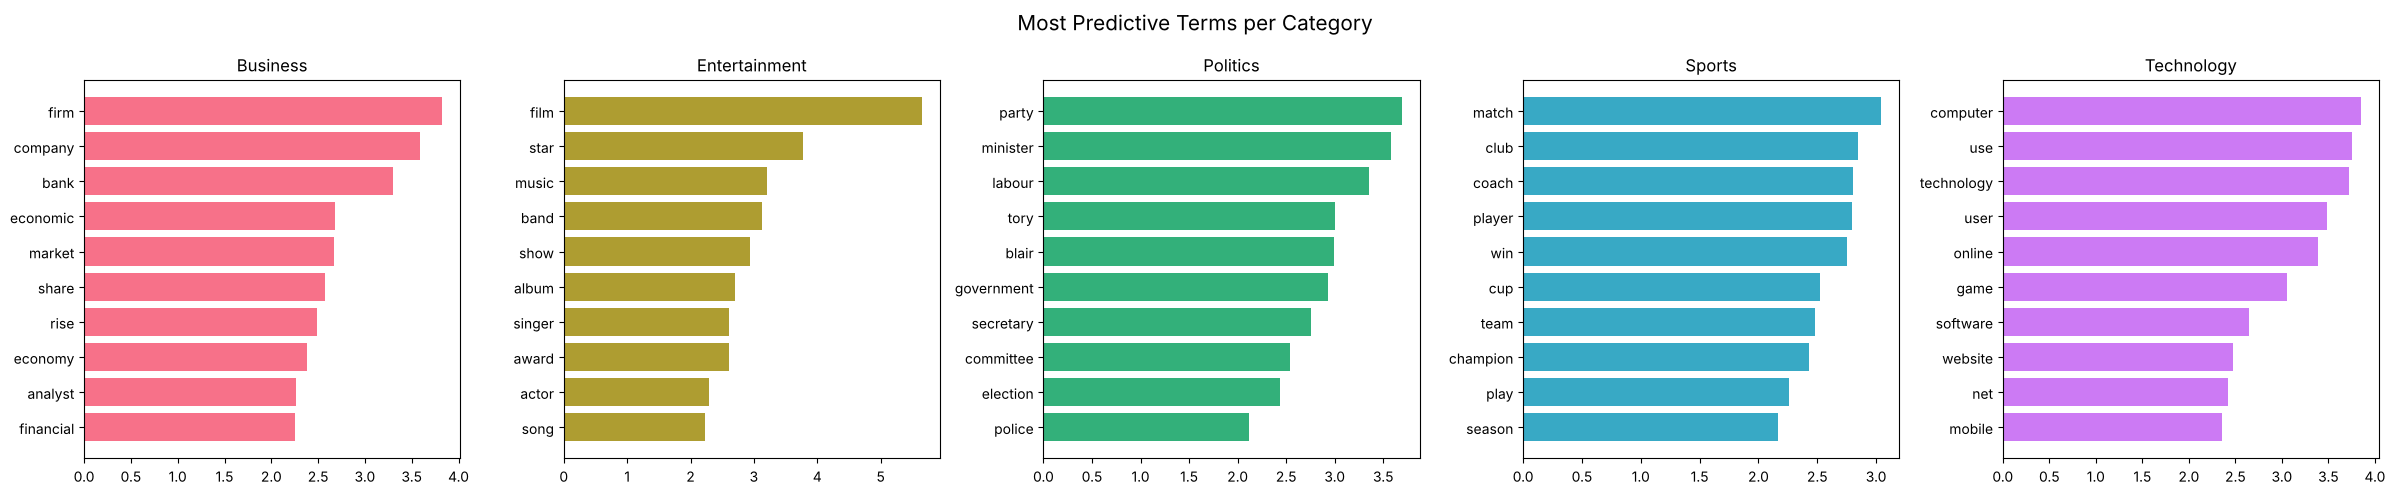


🧩 Linguistic features alone (no words at all) reach 72.8% test accuracy.
Most important engineered features:
pos_NOUN                    0.1086
ent_PERSON                  0.0729
ent_PERCENT                 0.0621
subordinate_per_sentence    0.0482
pos_PRON                    0.0476
ent_MONEY                   0.0466
pos_PROPN                   0.0457
char_length                 0.0401
pos_NUM                     0.0393
ent_GPE                     0.0381
word_count                  0.0354
sent_neg                    0.0350


In [28]:
# Feature importance: which TF-IDF terms push an article towards each category?
# We refit a Logistic Regression on TF-IDF features only, because its coefficients are directly interpretable.
interp = Pipeline([('tfidf', TfidfVectorizer(**BEST_TFIDF_PARAMS)),
                   ('clf', LogisticRegression(max_iter=2000, C=10))]).fit(X_train['full_text_processed'], y_train)
terms = interp.named_steps['tfidf'].get_feature_names_out()
coefs = interp.named_steps['clf'].coef_

fig, axes = plt.subplots(1, 5, figsize=(24, 5))
print("🔍 Top Features by Category (Logistic Regression coefficients):")
for i, (ax, class_name) in enumerate(zip(axes, interp.classes_)):
    top_idx = np.argsort(coefs[i])[-10:]
    print(f"  📰 {class_name}: {', '.join(terms[j] for j in reversed(top_idx))}")
    ax.barh(terms[top_idx], coefs[i][top_idx], color=CAT_COLORS[class_name])
    ax.set_title(class_name)
plt.suptitle('Most Predictive Terms per Category', fontsize=15)
plt.tight_layout()
plt.show()

# Which engineered features matter most? (Random Forest importance on linguistic features alone)
rf_meta = RandomForestClassifier(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train[META_COLS], y_train)
meta_only_acc = accuracy_score(y_test, rf_meta.predict(X_test[META_COLS]))
imp = pd.Series(rf_meta.feature_importances_, index=META_COLS).sort_values(ascending=False).head(12)
print(f"\n🧩 Linguistic features alone (no words at all) reach {meta_only_acc:.1%} test accuracy.")
print("Most important engineered features:")
print(imp.round(4).to_string())

### 📝 Classification Findings

* **All models perform well** because BBC categories have distinct vocabularies. Linear models win: **SVM** (98.25% CV) and **Logistic Regression** (98.19% CV) beat Naive Bayes (97.8%) and Random Forest (95.9%). Random Forests struggle with thousands of sparse TF-IDF features.
* **Final model:** a linear SVM tuned by grid search (C = 1, 15,000 features, sublinear TF), selected by cross validation and then checked once on the untouched test set: **96.75% accuracy, 0.967 macro F1**. Sports is almost perfect (F1 0.99); Politics is the hardest (F1 0.95).
* **Linguistic features did not help on top of TF-IDF.** Adding the 26 engineered features slightly lowered accuracy for the linear models. They are informative on their own (72.8% accuracy with no words at all, led by noun share, person and percent density), but TF-IDF already captures that information and the extra features add noise. We report this honestly instead of forcing them into the final model.
* **Feature selection:** keeping only the top 250 chi squared terms still gives 96.4% accuracy, so a much lighter model is possible if speed matters; using all features is best.
* **Class weighting** made no difference (macro F1 0.981 vs 0.982), which confirms the mild imbalance is not a problem.
* **The errors are understandable.** Most of the 13 misclassified test articles genuinely cross topics: *MPs issued with Blackberry threat* (Politics vs Technology), *McDonald's to sponsor MTV show* (Business vs Entertainment), *Ferdinand casts doubt over Glazer* (the Manchester United takeover, Sports vs Business). A multi label system would describe these better than a single label.

## 🔍 Named Entity Recognition

### 🎯 Module 8: Extracting Facts from News

NER turns unstructured text into structured, queryable records. We reuse the spaCy documents parsed in Module 5.

**NER Applications:**
* **Entity Tracking:** monitor mentions of people, organizations, locations
* **Fact Extraction:** build knowledge bases from news content
* **Relationship Mapping:** understand connections between entities
* **Entity Sentiment:** measure the tone of coverage around each entity

**💡 Business Value:** queries like *show me every article that mentions Microsoft together with a MONEY amount* or *how positive is the coverage of a given minister* become simple table lookups.

In [29]:
def extract_entities(text=None, doc=None):
    '''
    Extract named entities using spaCy. Pass raw text or a parsed doc.
    Returns a list of dicts with text, label, character offsets and a description of the label.
    '''
    if doc is None:
        if not text or pd.isna(text):
            return []
        doc = nlp(str(text))
    return [{'text': ent.text.strip(), 'label': ent.label_, 'start': ent.start_char, 'end': ent.end_char,
             'description': spacy.explain(ent.label_)} for ent in doc.ents]

def normalize_entity(text):
    # Light normalization so "the BBC" and "BBC" or "Blair's" and "Blair" count together
    text = re.sub(r"^(the|The)\s+", '', text)
    text = re.sub(r"['’]s$", '', text)
    return text.strip()

print("🔍 Extracting named entities...")
all_entities, article_entities = [], []
for doc, (_, row) in zip(docs, df.iterrows()):
    entities = extract_entities(doc=doc)
    article_entities.append({'article_id': row['article_id'], 'category': row['category'],
                             'entities': entities, 'entity_count': len(entities)})
    for entity in entities:
        entity['norm'] = normalize_entity(entity['text'])
        entity['article_id'] = row['article_id']
        entity['category'] = row['category']
        all_entities.append(entity)

entities_df = pd.DataFrame(all_entities)
KEY_TYPES = ['PERSON', 'ORG', 'GPE', 'DATE', 'MONEY']
key_entities_df = entities_df[entities_df['label'].isin(KEY_TYPES)]

print(f"✅ Entity extraction complete!")
print(f"📊 Total entities found: {len(entities_df):,} ({len(entities_df) / len(df):.1f} per article)")
print(f"📰 Articles processed: {len(article_entities)}")
print(f"🏷️ Entity types found: {sorted(entities_df['label'].unique())}")
print("\n📝 Sample entities from the first article:")
print(entities_df[entities_df['article_id'] == df['article_id'].iloc[0]][['text', 'label', 'description']].head(10).to_string(index=False))

🔍 Extracting named entities...


✅ Entity extraction complete!
📊 Total entities found: 82,803 (41.4 per article)
📰 Articles processed: 2000
🏷️ Entity types found: ['CARDINAL', 'DATE', 'EVENT', 'FAC', 'GPE', 'LANGUAGE', 'LAW', 'LOC', 'MONEY', 'NORP', 'ORDINAL', 'ORG', 'PERCENT', 'PERSON', 'PRODUCT', 'QUANTITY', 'TIME', 'WORK_OF_ART']

📝 Sample entities from the first article:
           text    label                                    description
       Lib Dems   PERSON                    People, including fictional
      Democrats     NORP Nationalities or religious or political groups
Charles Kennedy   PERSON                    People, including fictional
          years     DATE          Absolute or relative dates or periods
         Labour   PERSON                    People, including fictional
  Conservatives     NORP Nationalities or religious or political groups
        Kennedy   PERSON                    People, including fictional
    Two million CARDINAL   Numerals that do not fall under another type
       

📊 NAMED ENTITY ANALYSIS

🏷️ Entity type distribution (top 10):
label
PERSON      19351
ORG         17089
DATE        12240
GPE         11272
CARDINAL     7437
NORP         4288
MONEY        2493
ORDINAL      2188
PERCENT      1761
LOC          1012

📰 Key entity types per article, by news category:
label          PERSON    ORG   GPE  DATE  MONEY
category                                       
Business         4.89   9.36  6.48  7.47   2.82
Entertainment   12.73   7.50  4.70  6.45   1.33
Politics        10.88   8.31  4.70  5.38   0.89
Sports          14.23   6.70  7.13  5.73   0.16
Technology       5.41  11.43  4.31  5.19   0.82

🔥 Most frequent entities (PERSON, ORG, GPE):
  US (GPE): 1361 mentions
  UK (GPE): 920 mentions
  England (GPE): 473 mentions
  Labour (ORG): 403 mentions
  Britain (GPE): 359 mentions
  London (GPE): 346 mentions
  France (GPE): 295 mentions
  Blair (PERSON): 286 mentions
  BBC (ORG): 271 mentions
  EU (ORG): 263 mentions
  China (GPE): 247 mentions
  Ireland 

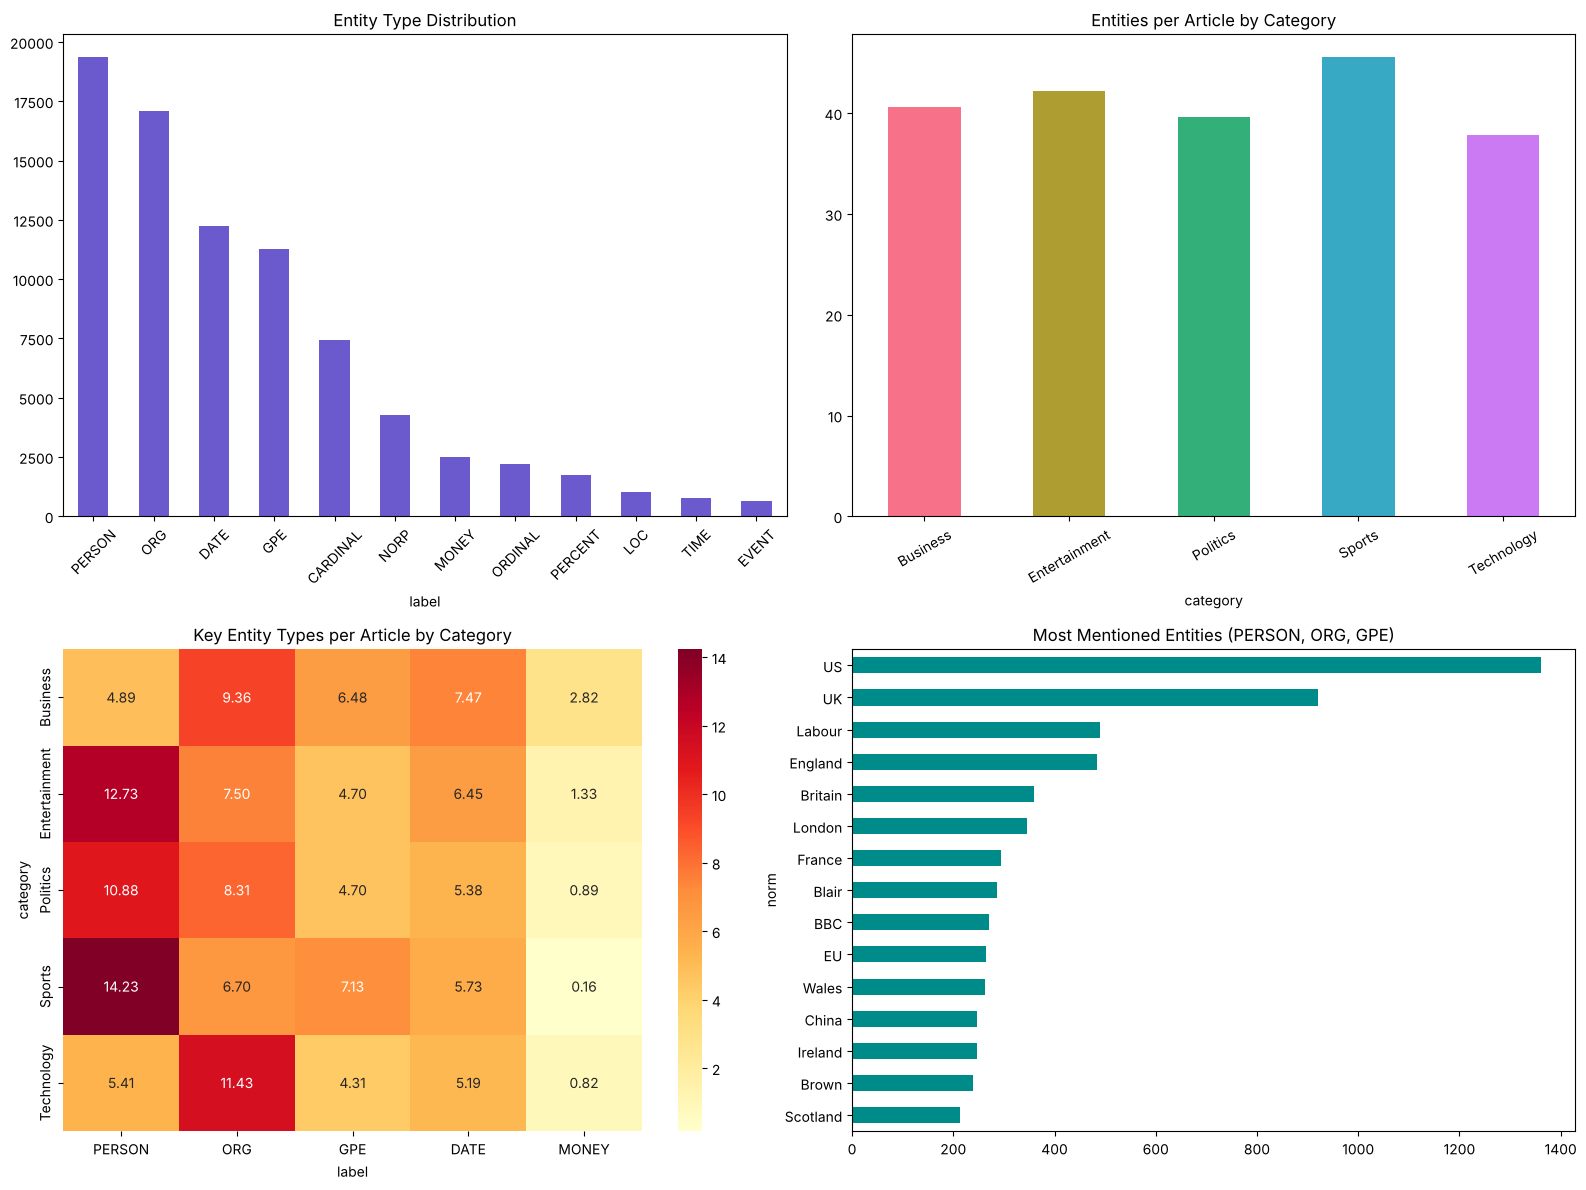

In [30]:
# Analyze entity patterns
print("📊 NAMED ENTITY ANALYSIS")
print("=" * 50)
entity_counts = entities_df['label'].value_counts()
print("\n🏷️ Entity type distribution (top 10):")
print(entity_counts.head(10).to_string())

# Normalize by article count so categories of different sizes are comparable
entity_by_category = key_entities_df.groupby(['category', 'label']).size().unstack(fill_value=0)[KEY_TYPES]
entity_per_article = entity_by_category.div(df['category'].value_counts(), axis=0)
print("\n📰 Key entity types per article, by news category:")
print(entity_per_article.round(2))

print("\n🔥 Most frequent entities (PERSON, ORG, GPE):")
frequent_entities = (key_entities_df[key_entities_df['label'].isin(['PERSON', 'ORG', 'GPE'])]
                     .groupby(['norm', 'label']).size().sort_values(ascending=False).head(15))
for (entity, label), count in frequent_entities.items():
    print(f"  {entity} ({label}): {count} mentions")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
entity_counts.head(12).plot(kind='bar', ax=axes[0, 0], color='slateblue')
axes[0, 0].set_title('Entity Type Distribution')
axes[0, 0].tick_params(axis='x', rotation=45)

(entities_df.groupby('category').size() / df['category'].value_counts()).reindex(CATEGORY_ORDER).plot(
    kind='bar', ax=axes[0, 1], color=[CAT_COLORS[c] for c in CATEGORY_ORDER])
axes[0, 1].set_title('Entities per Article by Category')
axes[0, 1].tick_params(axis='x', rotation=30)

sns.heatmap(entity_per_article, annot=True, fmt='.2f', ax=axes[1, 0], cmap='YlOrRd')
axes[1, 0].set_title('Key Entity Types per Article by Category')

top_people_orgs = (key_entities_df[key_entities_df['label'].isin(['PERSON', 'ORG', 'GPE'])]['norm']
                   .value_counts().head(15))
top_people_orgs[::-1].plot(kind='barh', ax=axes[1, 1], color='darkcyan')
axes[1, 1].set_title('Most Mentioned Entities (PERSON, ORG, GPE)')
plt.tight_layout()
plt.show()

In [31]:
# Cross category entity patterns: the leading entities of each type in each category
print("🗂️ TOP ENTITIES BY CATEGORY AND TYPE (number of articles mentioning them)")
for cat in CATEGORY_ORDER:
    print(f"\n📰 {cat.upper()}")
    sub = key_entities_df[key_entities_df['category'] == cat].drop_duplicates(['article_id', 'norm', 'label'])
    for label in ['PERSON', 'ORG', 'GPE', 'MONEY']:
        top = sub[sub['label'] == label]['norm'].value_counts().head(5)
        print(f"  {label:7s}: " + ', '.join(f"{e} ({c})" for e, c in top.items()))

# Entities that appear across many categories (cross cutting actors)
spread = (key_entities_df[key_entities_df['label'].isin(['PERSON', 'ORG', 'GPE'])]
          .groupby('norm')['category'].agg(['nunique', 'count']))
print("\n🌐 Cross cutting entities (mentioned in all 5 categories, most mentions first):")
print(spread[spread['nunique'] == 5].sort_values('count', ascending=False).head(10).to_string())

🗂️ TOP ENTITIES BY CATEGORY AND TYPE (number of articles mentioning them)

📰 BUSINESS
  PERSON : Yukos (25), Mikhail Khodorkovsky (17), George W Bush (16), Bush (16), Vladimir Putin (12)
  ORG    : Reuters (43), EU (23), European Union (23), BBC (22), Bank of England (20)
  GPE    : US (235), UK (99), China (58), London (54), India (43)
  MONEY  : 1bn (15), 1.5bn (12), 500 (10), 800 (8), 1.3bn (8)

📰 ENTERTAINMENT
  PERSON : Oscar (63), Martin Scorsese (23), Imelda Staunton (18), Ray (17), Kate Winslet (16)
  ORG    : BBC (45), Oscars (27), Vera Drake (19), Academy Awards (16), U2 (14)
  GPE    : US (146), UK (106), London (65), Hollywood (56), Los Angeles (41)
  MONEY  : 50,000 (5), 9 (5), Million Dollar Baby (5), 50 Cent (4), 550,000 (4)

📰 POLITICS
  PERSON : Tony Blair (131), Blair (93), Michael Howard (90), Gordon Brown (67), Labour (60)
  ORG    : Labour (146), BBC (57), Parliament (50), BBC Radio 4 (47), BBC News (37)
  GPE    : UK (135), Britain (125), London (61), England (53)

🕸️ Co-occurrence network: 34 entities, 175 links (8+ shared articles)
Strongest relationships:
  UK <-> US: 146 articles
  London <-> UK: 105 articles
  Britain <-> UK: 100 articles
  England <-> Wales: 88 articles
  Blair <-> Tony Blair: 87 articles
  Labour <-> Tony Blair: 82 articles
  Britain <-> Labour: 69 articles
  Labour <-> Michael Howard: 64 articles
  New York <-> US: 58 articles
  Michael Howard <-> Tony Blair: 57 articles
Most connected entities: UK (0.85), US (0.76), London (0.61), Britain (0.58), Labour (0.45), England (0.45)


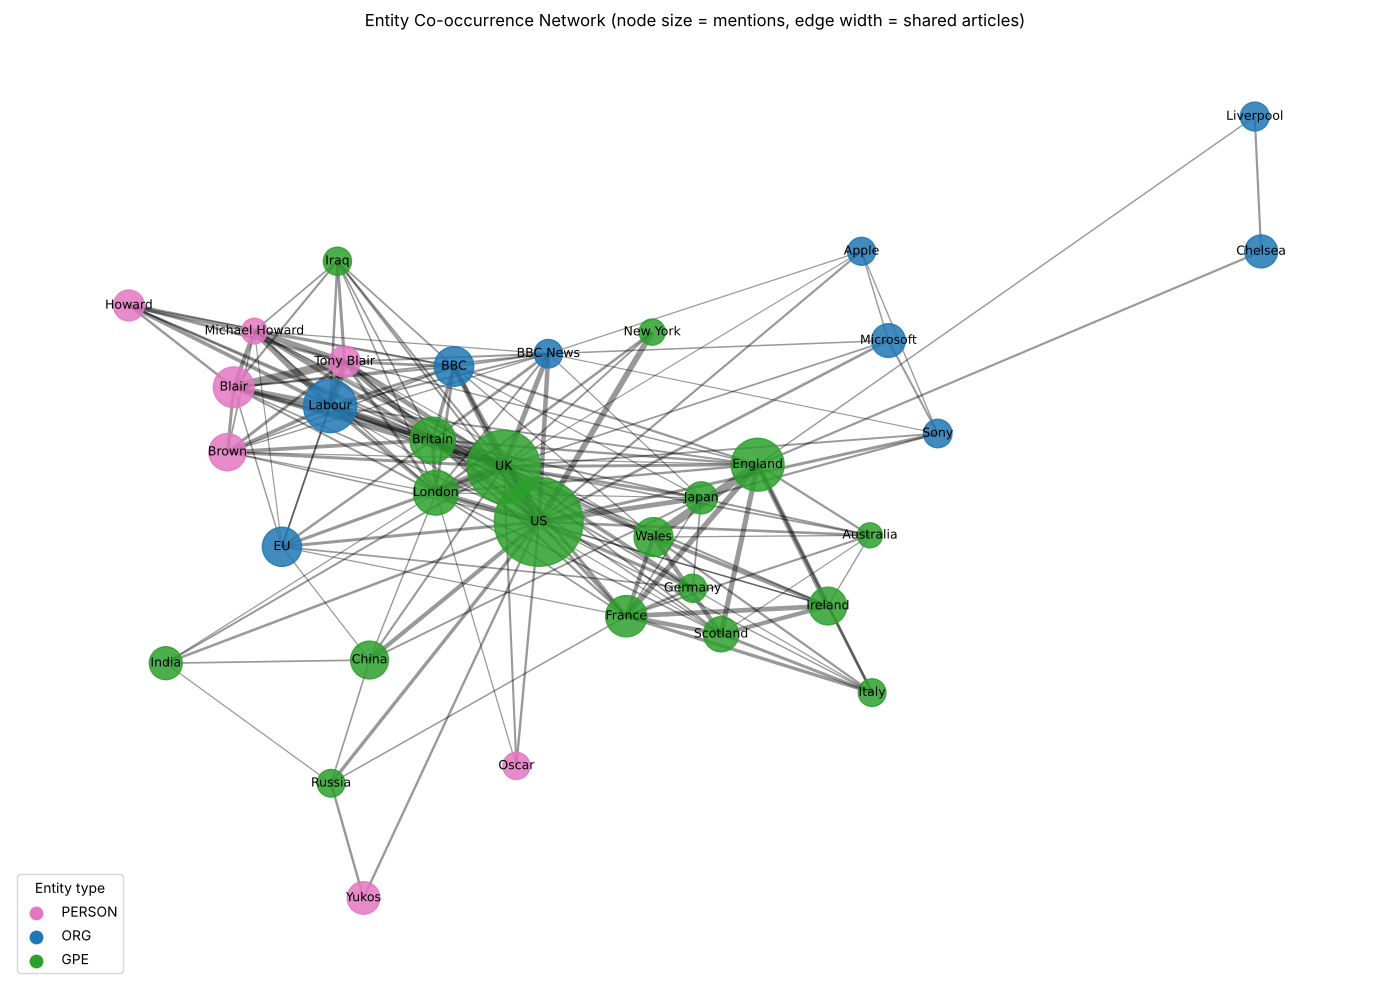

In [32]:
# Entity relationship mapping: co-occurrence network of the most mentioned people and organizations
net_df = key_entities_df[key_entities_df['label'].isin(['PERSON', 'ORG', 'GPE'])]
top_nodes = net_df['norm'].value_counts().head(35).index
node_label = net_df[net_df['norm'].isin(top_nodes)].groupby('norm')['label'].agg(lambda s: s.mode()[0])

pair_counts = Counter()
for _, group in net_df[net_df['norm'].isin(top_nodes)].groupby('article_id'):
    ents = sorted(set(group['norm']))
    pair_counts.update(combinations(ents, 2))

G = nx.Graph()
for ent in top_nodes:
    G.add_node(ent, label=node_label[ent], size=int((net_df['norm'] == ent).sum()))
for (a, b), w in pair_counts.items():
    if w >= 8:
        G.add_edge(a, b, weight=w)
G.remove_nodes_from([n for n in list(G.nodes) if G.degree(n) == 0])

print(f"🕸️ Co-occurrence network: {G.number_of_nodes()} entities, {G.number_of_edges()} links (8+ shared articles)")
print("Strongest relationships:")
for (a, b), w in pair_counts.most_common(10):
    print(f"  {a} <-> {b}: {w} articles")
centrality = nx.degree_centrality(G)
print("Most connected entities: " + ', '.join(f"{n} ({c:.2f})" for n, c in
                                               sorted(centrality.items(), key=lambda x: -x[1])[:6]))

plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, k=0.9, seed=RANDOM_STATE, weight='weight')
color_map = {'PERSON': '#e377c2', 'ORG': '#1f77b4', 'GPE': '#2ca02c'}
nx.draw_networkx_edges(G, pos, width=[0.3 + G[u][v]['weight'] / 15 for u, v in G.edges], alpha=0.4)
nx.draw_networkx_nodes(G, pos, node_color=[color_map[G.nodes[n]['label']] for n in G.nodes],
                       node_size=[G.nodes[n]['size'] * 3 for n in G.nodes], alpha=0.85)
nx.draw_networkx_labels(G, pos, font_size=9)
for lab, col in color_map.items():
    plt.scatter([], [], color=col, label=lab, s=80)
plt.legend(title='Entity type', loc='lower left')
plt.title('Entity Co-occurrence Network (node size = mentions, edge width = shared articles)')
plt.axis('off')
plt.tight_layout()
plt.show()

😊 ENTITY SENTIMENT (mean VADER score of sentences mentioning the entity, 25+ mentions)

Most negative coverage:
                   mean  count
entity    label               
WorldCom  ORG    -0.316     44
Kenteris  PERSON -0.258     42
Sullivan  PERSON -0.243     25
Chicago   GPE    -0.198     25
Yukos     PERSON -0.192    171
Sri Lanka GPE    -0.186     26
Indonesia GPE    -0.177     45
Iran      GPE    -0.151     30

Most positive coverage:
                          mean  count
entity           label               
Labour Party     ORG     0.434     43
Martin Scorsese  PERSON  0.465     31
Joss Stone       PERSON  0.503     33
Imelda Staunton  PERSON  0.514     27
Ray              PERSON  0.528     27
Bafta            GPE     0.546     27
Champions League ORG     0.603     66
Vera Drake       ORG     0.638     35


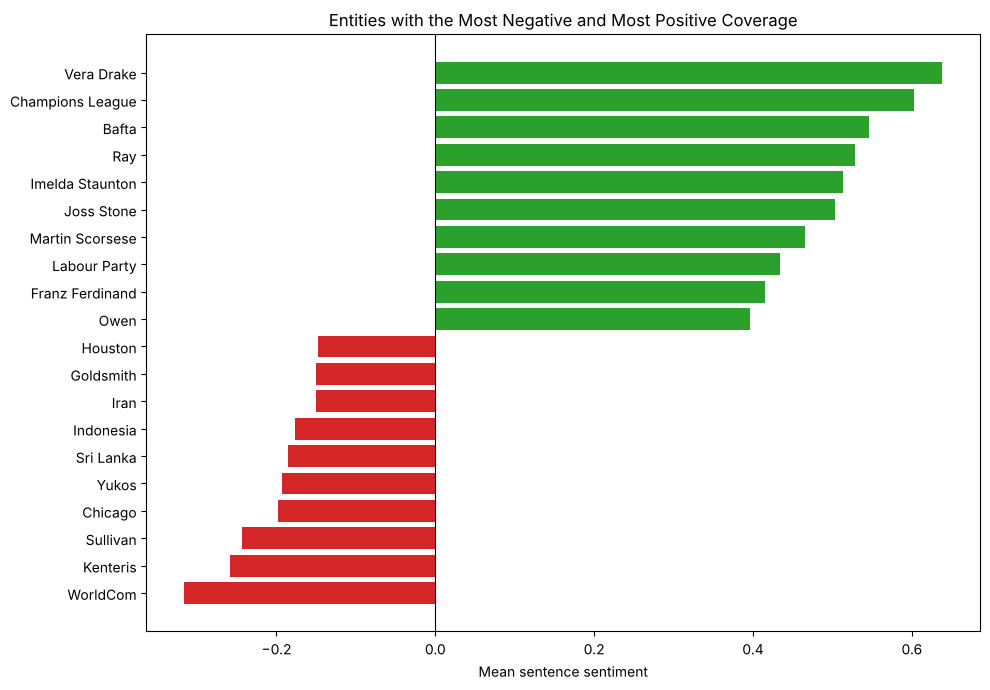


💰 Sample MONEY facts from business articles:
                            title                 text
Swiss cement firm in buying spree                $800m
Swiss cement firm in buying spree                  429
Swiss cement firm in buying spree                1.8bn
 China bans new tobacco factories                1.5bn
 China bans new tobacco factories                  800
 China bans new tobacco factories more than 210bn yuan
 China bans new tobacco factories               25.4bn
  Deadline nears for Fiat-GM deal           about $2bn


In [33]:
# Entity sentiment associations: tone of the coverage around frequently mentioned entities
# For each mention we score the sentence the entity appears in (more precise than the whole article).
ent_sent_rows = []
for doc, (_, row) in zip(docs, df.iterrows()):
    for ent in doc.ents:
        if ent.label_ in ('PERSON', 'ORG', 'GPE'):
            ent_sent_rows.append({'entity': normalize_entity(ent.text), 'label': ent.label_,
                                  'category': row['category'],
                                  'sentence_sentiment': sia.polarity_scores(ent.sent.text)['compound']})
ent_sent_df = pd.DataFrame(ent_sent_rows)
ent_tone = (ent_sent_df.groupby(['entity', 'label'])['sentence_sentiment']
            .agg(['mean', 'count']).query('count >= 25').sort_values('mean'))

print("😊 ENTITY SENTIMENT (mean VADER score of sentences mentioning the entity, 25+ mentions)")
print("\nMost negative coverage:")
print(ent_tone.head(8).round(3).to_string())
print("\nMost positive coverage:")
print(ent_tone.tail(8).round(3).to_string())

plot_df = pd.concat([ent_tone.head(10), ent_tone.tail(10)]).reset_index()
plt.figure(figsize=(10, 7))
plt.barh(plot_df['entity'], plot_df['mean'],
         color=['#d62728' if v < 0 else '#2ca02c' for v in plot_df['mean']])
plt.axvline(0, color='black', lw=0.8)
plt.title('Entities with the Most Negative and Most Positive Coverage')
plt.xlabel('Mean sentence sentiment')
plt.tight_layout()
plt.show()

# MONEY entities in business news: example of structured fact extraction
money_facts = (entities_df[(entities_df['label'] == 'MONEY') & (entities_df['category'] == 'Business')]
               .merge(df[['article_id', 'title']], on='article_id').head(8))
print("\n💰 Sample MONEY facts from business articles:")
print(money_facts[['title', 'text']].to_string(index=False))

### 📝 NER Findings

* **Volume:** 82,803 entities (41 per article) across 18 types; PERSON, ORG, DATE and GPE dominate.
* **Cross category patterns:** Sports (14.2 people per article) and Entertainment (12.7) are about people; Technology (11.4 organizations per article) and Business (9.4) are about organizations; Business carries the most MONEY (2.8 per article) and DATE mentions. The UK and US appear in every category, making them the hubs of the co-occurrence network.
* **Relationships:** the network recovers real structure without supervision: a political cluster (*Tony Blair, Labour, Michael Howard, Gordon Brown*), a sports cluster (*England, Wales, Ireland, Scotland, France*, the Six Nations) and a tech cluster (*Microsoft, Apple, Sony*).
* **Entity sentiment:** the most negatively covered entities match real 2004/05 stories (WorldCom fraud, the Kenteris doping case, Yukos), and the most positive are award winners (*Vera Drake, Imelda Staunton, Martin Scorsese*) and the Champions League. This is exactly the reputation signal a PR team would want.
* **Limitations of the small spaCy model:** it confuses types in this domain, tagging *Labour* and *Yukos* as PERSON, clubs such as *Manchester United* as PERSON, *Oscar* as a person and film titles (*Million Dollar Baby*) or the rapper *50 Cent* as MONEY. Title Case headlines also produce false organizations (see the test articles below). A larger model (en_core_web_lg or a transformer), an EntityRuler with domain lists, and processing headlines separately would fix most of these.

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Here we combine every module into one report.

**Key Analysis Areas:**
1. **Cross Category Patterns:** how do news types differ linguistically?
2. **Entity Sentiment Relationships:** which entities get positive or negative coverage?
3. **Content Quality Metrics:** which categories are the most information dense?
4. **Classification Performance:** how well can we categorize news automatically?

In [34]:
def create_comprehensive_analysis():
    '''
    Generate comprehensive insights combining classification performance, sentiment patterns,
    emotion profiles, entity distributions and linguistic features.
    '''
    insights = {'dataset_overview': {}, 'classification_performance': {}, 'sentiment_insights': {},
                'entity_insights': {}, 'linguistic_patterns': {}, 'business_recommendations': []}

    insights['dataset_overview'] = {
        'total_articles': len(df),
        'categories': sorted(df['category'].unique().tolist()),
        'category_distribution': df['category'].value_counts().to_dict(),
        'avg_article_length': df['full_text'].str.len().mean(),
        'avg_words_per_article': df['full_text'].str.split().str.len().mean(),
    }

    insights['classification_performance'] = {
        'best_model': best_model_name,
        'best_accuracy': results[best_model_name]['accuracy'],
        'best_macro_f1': results[best_model_name]['f1_macro'],
        'model_comparison': {k: round(r['accuracy'], 4) for k, r in results.items()},
    }

    sentiment_by_cat = sentiment_df.groupby('category')['sent_mean'].mean().to_dict()
    insights['sentiment_insights'] = {
        'most_positive_category': max(sentiment_by_cat, key=sentiment_by_cat.get),
        'most_negative_category': min(sentiment_by_cat, key=sentiment_by_cat.get),
        'sentiment_by_category': sentiment_by_cat,
        'overall_sentiment': sentiment_df['sent_mean'].mean(),
        'dominant_emotion_by_category': (emotion_by_cat / emotion_by_cat.mean()).idxmax(axis=1).to_dict(),
    }

    insights['entity_insights'] = {
        'total_entities': len(entities_df),
        'unique_entities': entities_df['norm'].nunique(),
        'entity_types': sorted(entities_df['label'].unique().tolist()),
        'entities_per_article_by_category': (entities_df.groupby('category').size() / df['category'].value_counts()).round(1).to_dict(),
        'most_mentioned_entities': key_entities_df[key_entities_df['label'].isin(['PERSON', 'ORG', 'GPE'])]['norm'].value_counts().head(5).to_dict(),
        'most_negative_entity': ent_tone.index[0][0],
        'most_positive_entity': ent_tone.index[-1][0],
    }

    syn = syntax_df.groupby('category')[['avg_sentence_length', 'subordinate_per_sentence']].mean()
    grp = group_means
    insights['linguistic_patterns'] = {
        'most_proper_nouns': grp['Proper nouns'].idxmax(),
        'most_numbers': grp['Numbers'].idxmax(),
        'most_past_tense': grp['Past tense verbs'].idxmax(),
        'most_adjectives': grp['Adjectives'].idxmax(),
        'longest_sentences': syn['avg_sentence_length'].idxmax(),
        'most_complex_syntax': syn['subordinate_per_sentence'].idxmax(),
    }

    rec = []
    acc = insights['classification_performance']['best_accuracy']
    if acc > 0.95:
        rec.append(f"✅ {acc:.1%} test accuracy: ready for automated content routing, with low confidence predictions sent to an editor")
    elif acc > 0.8:
        rec.append(f"✅ {acc:.1%} accuracy: suitable for assisted tagging with human review")
    else:
        rec.append("⚠️ Classification accuracy needs improvement: more training data or feature engineering")
    s = insights['sentiment_insights']
    rec.append(f"📊 {s['most_positive_category']} coverage is the most positive: a good source for uplifting recommendations")
    rec.append(f"📊 {s['most_negative_category']} coverage is the most negative: monitor for balance and audience fatigue")
    lp = insights['linguistic_patterns']
    rec.append(f"🔢 {lp['most_numbers']} articles are the most number dense: prioritize MONEY/PERCENT extraction for financial dashboards")
    rec.append(f"👤 {lp['most_proper_nouns']} articles carry the most proper nouns: entity tracking gives the most value there")
    rec.append("🔍 Entity level sentiment enables reputation dashboards for people and organizations")
    insights['business_recommendations'] = rec
    return insights

print("📊 Generating comprehensive analysis...")
analysis_results = create_comprehensive_analysis()
print("✅ Analysis complete!")
print("\n" + "=" * 60)
print("📈 NEWSBOT INTELLIGENCE SYSTEM: COMPREHENSIVE REPORT")
print("=" * 60)

o = analysis_results['dataset_overview']
print(f"\n📊 DATASET OVERVIEW:")
print(f"  Total Articles: {o['total_articles']}")
print(f"  Categories: {', '.join(o['categories'])}")
print(f"  Average Article Length: {o['avg_article_length']:.0f} characters")
print(f"  Average Words per Article: {o['avg_words_per_article']:.0f} words")

p = analysis_results['classification_performance']
print(f"\n🤖 CLASSIFICATION PERFORMANCE:")
print(f"  Best Model: {p['best_model']}")
print(f"  Test Accuracy: {p['best_accuracy']:.4f}   Macro F1: {p['best_macro_f1']:.4f}")

s = analysis_results['sentiment_insights']
print(f"\n😊 SENTIMENT INSIGHTS:")
print(f"  Most Positive Category: {s['most_positive_category']}")
print(f"  Most Negative Category: {s['most_negative_category']}")
print(f"  Overall Sentiment: {s['overall_sentiment']:.4f}")
print(f"  Most over represented emotion: " + ', '.join(f"{c}: {e}" for c, e in s['dominant_emotion_by_category'].items()))

e = analysis_results['entity_insights']
print(f"\n🔍 ENTITY INSIGHTS:")
print(f"  Total Entities: {e['total_entities']:,}   Unique Entities: {e['unique_entities']:,}")
print(f"  Most mentioned: {', '.join(e['most_mentioned_entities'])}")
print(f"  Most negative coverage: {e['most_negative_entity']}   Most positive coverage: {e['most_positive_entity']}")

l = analysis_results['linguistic_patterns']
print(f"\n✍️ LINGUISTIC PATTERNS:")
for k, v in l.items():
    print(f"  {k.replace('_', ' ').capitalize()}: {v}")

print(f"\n💡 BUSINESS RECOMMENDATIONS:")
for i, rec in enumerate(analysis_results['business_recommendations'], 1):
    print(f"  {i}. {rec}")

📊 Generating comprehensive analysis...
✅ Analysis complete!

📈 NEWSBOT INTELLIGENCE SYSTEM: COMPREHENSIVE REPORT

📊 DATASET OVERVIEW:
  Total Articles: 2000
  Categories: Business, Entertainment, Politics, Sports, Technology
  Average Article Length: 2269 characters
  Average Words per Article: 386 words

🤖 CLASSIFICATION PERFORMANCE:
  Best Model: SVM (tuned) | TF-IDF only
  Test Accuracy: 0.9675   Macro F1: 0.9671

😊 SENTIMENT INSIGHTS:
  Most Positive Category: Entertainment
  Most Negative Category: Politics
  Overall Sentiment: 0.0895
  Most over represented emotion: Business: trust, Entertainment: joy, Politics: fear, Sports: sadness, Technology: fear

🔍 ENTITY INSIGHTS:
  Total Entities: 82,803   Unique Entities: 21,834
  Most mentioned: US, UK, Labour, England, Britain
  Most negative coverage: WorldCom   Most positive coverage: Vera Drake

✍️ LINGUISTIC PATTERNS:
  Most proper nouns: Entertainment
  Most numbers: Business
  Most past tense: Politics
  Most adjectives: Technolo

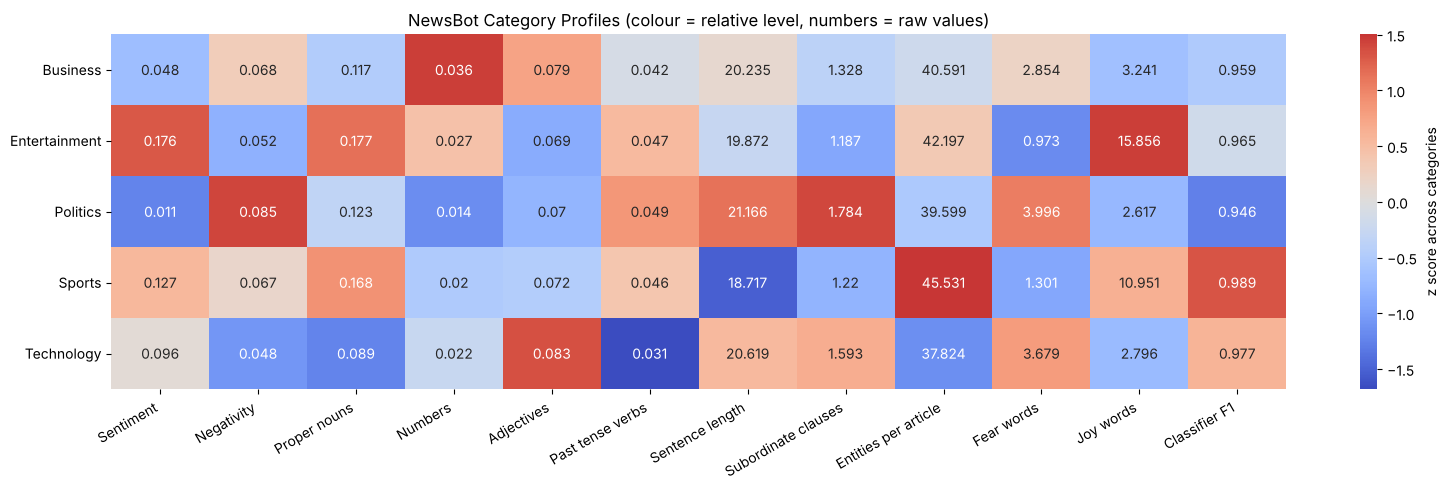

In [35]:
# Category profile dashboard: one standardized view across all modules
profile = pd.DataFrame({
    'Sentiment': sentiment_df.groupby('category')['sent_mean'].mean(),
    'Negativity': sentiment_df.groupby('category')['neg_score'].mean(),
    'Proper nouns': group_means['Proper nouns'],
    'Numbers': group_means['Numbers'],
    'Adjectives': group_means['Adjectives'],
    'Past tense verbs': group_means['Past tense verbs'],
    'Sentence length': syntax_df.groupby('category')['avg_sentence_length'].mean(),
    'Subordinate clauses': syntax_df.groupby('category')['subordinate_per_sentence'].mean(),
    'Entities per article': entities_df.groupby('category').size() / df['category'].value_counts(),
    'Fear words': emotion_by_cat['fear'],
    'Joy words': emotion_by_cat['joy'],
    'Classifier F1': pd.Series(classification_report(y_test, best_predictions, output_dict=True)).loc[CATEGORY_ORDER].apply(lambda d: d['f1-score']),
}).loc[CATEGORY_ORDER]
z = (profile - profile.mean()) / profile.std()

plt.figure(figsize=(16, 5))
sns.heatmap(z, annot=profile.round(3), fmt='', cmap='coolwarm', center=0,
            cbar_kws={'label': 'z score across categories'})
plt.title('NewsBot Category Profiles (colour = relative level, numbers = raw values)')
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 📝 Integrated Insights

The profile dashboard shows that every category has a distinct linguistic fingerprint that is consistent across modules:

| Category | Fingerprint | Business use |
|:---|:---|:---|
| **Business** | Numbers, money, organizations, trust and anticipation words, slightly negative | Feed MONEY and ORG facts into financial monitoring dashboards |
| **Entertainment** | Names, superlatives, joy, the most positive tone | Celebrity and brand reputation tracking, uplifting content recommendations |
| **Politics** | Long sentences, reported speech, modals, fear words, the most negative tone and headlines | Bias and framing monitoring; the hardest category to classify, so keep a human in the loop |
| **Sports** | Short active sentences, names and pronouns, joy, near perfect classification | Fully automated routing and results extraction |
| **Technology** | Common nouns, adjectives, relative clauses, products and companies | Product launch and competitor tracking |

The modules reinforce each other: the POS finding that Business is number heavy matches the NER finding that it has the most MONEY entities; the syntax finding that Politics relies on reported speech matches its high verb and modal usage; and the sentiment finding that Entertainment is the most positive matches its joy dominated emotion profile.

## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

The NewsBotIntelligenceSystem class wraps every module into one object that processes a new article from start to finish.

**Complete Pipeline:**
1. **Text Preprocessing:** clean and normalize input (Module 2)
2. **Parsing:** one spaCy pass for POS, dependencies and entities (Modules 4, 5, 8)
3. **Feature Extraction:** TF-IDF plus the same engineered features used in training (Modules 3, 7)
4. **Classification:** category with calibrated probabilities and an out of scope flag (Module 7)
5. **Entity Extraction:** people, organizations, places, dates and money (Module 8)
6. **Sentiment and Emotion:** tone at article and sentence level (Module 6)
7. **Semantic Roles:** key who did what to whom events (Module 5)
8. **Insight Generation:** actionable flags for editors and analysts

**💡 Production Ready:** the class can be wrapped in a REST API, a batch job or a Streamlit dashboard.

In [36]:
class NewsBotIntelligenceSystem:
    '''
    Complete NewsBot Intelligence System.
    Encapsulates preprocessing, the trained classification pipeline, entity extraction,
    sentiment and emotion analysis, semantic role extraction and insight generation.
    '''
    CONFIDENCE_THRESHOLD = 0.60   # below this, the article is flagged for manual review

    def __init__(self, classifier, sentiment_analyzer, nlp_model):
        self.classifier = classifier             # full sklearn Pipeline (features + model)
        self.sentiment_analyzer = sentiment_analyzer
        self.nlp = nlp_model

    def preprocess_article(self, title, content):
        '''Combine title and content and produce the preprocessed text used by TF-IDF.'''
        full_text = f"{title}. {content}"
        return full_text, preprocess_text(full_text)

    def classify_article(self, title, full_text, processed_text, doc):
        '''Classify with exactly the same features used during training (no dummy values).'''
        row = {'full_text_processed': processed_text, **compute_meta_features(title, full_text, doc)}
        features = pd.DataFrame([row])
        prediction = self.classifier.predict(features)[0]
        probabilities = self.classifier.predict_proba(features)[0]
        return prediction, dict(zip(self.classifier.classes_, probabilities))

    def extract_entities(self, doc):
        return extract_entities(doc=doc)

    def analyze_sentiment(self, full_text, doc):
        result = analyze_sentiment(full_text, doc=doc)
        result['emotions'] = emotion_profile(doc)
        return result

    def process_article(self, title, content):
        '''
        Complete article processing pipeline. Returns predicted category with confidence and
        probabilities, entities, sentiment and emotions, key events and insights.
        '''
        full_text, processed_text = self.preprocess_article(title, content)
        doc = self.nlp(full_text)                                   # single parse reused below
        category, category_probs = self.classify_article(title, full_text, processed_text, doc)
        entities = self.extract_entities(doc)
        sentiment = self.analyze_sentiment(full_text, doc)
        events = extract_semantic_roles(doc)
        insights = self.generate_insights(category, entities, sentiment, category_probs)
        return {
            'title': title,
            'content': content[:200] + '...' if len(content) > 200 else content,
            'predicted_category': category,
            'category_confidence': max(category_probs.values()),
            'category_probabilities': category_probs,
            'entities': entities,
            'sentiment': sentiment,
            'events': events,
            'insights': insights,
        }

    def process_batch(self, articles):
        '''Process a list of {'title', 'content'} dicts and return a summary DataFrame.'''
        rows = []
        for a in articles:
            r = self.process_article(a['title'], a['content'])
            rows.append({'title': r['title'], 'category': r['predicted_category'],
                         'confidence': round(r['category_confidence'], 3),
                         'sentiment': r['sentiment']['sentiment_label'],
                         'sentiment_score': round(r['sentiment']['sent_mean'], 3),
                         'entities': len(r['entities']),
                         'review': r['category_confidence'] < self.CONFIDENCE_THRESHOLD})
        return pd.DataFrame(rows)

    def generate_insights(self, category, entities, sentiment, category_probs):
        '''Generate actionable insights from the analysis results.'''
        insights = []
        ranked = sorted(category_probs.items(), key=lambda x: -x[1])
        confidence = ranked[0][1]
        if confidence >= 0.8:
            insights.append(f"✅ High confidence {category} classification ({confidence:.1%}): route automatically")
        elif confidence >= self.CONFIDENCE_THRESHOLD:
            insights.append(f"🟡 Moderate confidence {category} ({confidence:.1%}); runner up {ranked[1][0]} ({ranked[1][1]:.1%})")
        else:
            insights.append(f"⚠️ Uncertain classification ({confidence:.1%}, runner up {ranked[1][0]}): "
                            f"manual review, possibly out of scope or cross topic")

        score = sentiment['sent_mean']
        if score > 0.1:
            insights.append(f"😊 Positive tone ({score:.3f})")
        elif score < -0.1:
            insights.append(f"😞 Negative tone ({score:.3f}): consider for risk or reputation monitoring")
        else:
            insights.append(f"😐 Neutral, factual tone ({score:.3f})")
        emotions = sentiment['emotions']
        top_emotion = max(emotions, key=emotions.get)
        if emotions[top_emotion] > 0:
            insights.append(f"🎭 Dominant emotion: {top_emotion} ({emotions[top_emotion]:.1f} words per 1,000)")

        if entities:
            types = Counter(e['label'] for e in entities)
            insights.append(f"🔍 Found {len(entities)} entities of {len(types)} types")
            key = list(dict.fromkeys(e['text'] for e in entities if e['label'] in ('PERSON', 'ORG', 'GPE')))
            if key:
                insights.append(f"🎯 Key entities: {', '.join(key[:4])}")
            money = [e['text'] for e in entities if e['label'] == 'MONEY']
            if money:
                insights.append(f"💰 Financial figures mentioned: {', '.join(money[:3])}")
        else:
            insights.append("ℹ️ No named entities detected")
        return insights

# Initialize the complete system
newsbot = NewsBotIntelligenceSystem(classifier=best_model, sentiment_analyzer=sia, nlp_model=nlp)
print("🤖 NewsBot Intelligence System initialized!")
print(f"   Engine: {best_model_name}")
print("✅ Ready to process new articles")

🤖 NewsBot Intelligence System initialized!
   Engine: SVM (tuned) | TF-IDF only
✅ Ready to process new articles


In [37]:
# Test the complete system with NEW articles that are not in the training data
print("🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM")
print("=" * 60)

test_articles = [
    {'title': 'Microsoft Acquires AI Startup for $2 Billion',
     'content': "Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. "
                "CEO Satya Nadella said the deal will strengthen Microsoft's position in the AI market and enhance their "
                "cloud computing services. Shares rose 3% in early trading in New York."},
    {'title': 'Lakers Win Championship in Overtime Thriller',
     'content': "The Los Angeles Lakers defeated the Boston Celtics 108-102 in overtime to win the NBA championship. "
                "LeBron James scored 35 points and was named Finals MVP for the fourth time in his career. "
                "The coach praised the squad's resilience after they came back from a 15 point deficit."},
    {'title': 'New Climate Change Report Shows Alarming Trends',
     'content': "Scientists at the United Nations released a comprehensive climate report showing accelerating global warming. "
                "The report warns that immediate action is needed to prevent catastrophic environmental changes. "
                "Ministers from 40 countries will meet in Geneva next month to discuss new emissions targets."},
    {'title': 'Streaming Drama Sweeps Television Awards',
     'content': "A gritty crime drama from a small streaming service won five prizes at Sunday night's television awards, "
                "including best actress and best series. The show's director thanked the cast and said the win proved "
                "that audiences want bold storytelling. The ceremony in London was watched by four million viewers."},
    {'title': 'Opposition Demands Inquiry Into Hospital Waiting Lists',
     'content': "The opposition leader called for an independent inquiry after official figures showed hospital waiting "
                "lists reached a record high. The health secretary defended the government's record and promised an "
                "extra £1.5bn of funding before the general election, but critics said the plan was too little, too late."},
    {'title': 'Chipmaker Unveils Faster Smartphone Processor',
     'content': "A leading chipmaker unveiled a new mobile processor that it says is 40% faster and uses less battery than "
                "its predecessor. The chip, built on a 3 nanometre process, will appear in smartphones from several "
                "manufacturers early next year. Analysts said the launch could also lift the company's quarterly revenue."},
]

for i, article in enumerate(test_articles, 1):
    print(f"\n📰 TEST ARTICLE {i}")
    print("-" * 40)
    result = newsbot.process_article(article['title'], article['content'])
    print(f"📰 Title: {result['title']}")
    print(f"📝 Content: {result['content']}")
    print(f"\n🏷️ Predicted Category: {result['predicted_category']} ({result['category_confidence']:.2%} confidence)")
    print("📊 Category Probabilities: " + ', '.join(
        f"{c} {p:.3f}" for c, p in sorted(result['category_probabilities'].items(), key=lambda x: -x[1])))
    print(f"😊 Sentiment: {result['sentiment']['sentiment_label']} (article score {result['sentiment']['sent_mean']:.3f}, "
          f"VADER compound {result['sentiment']['compound']:.3f})")
    if result['entities']:
        print(f"🔍 Entities Found ({len(result['entities'])}): " + '; '.join(
            f"{e['text']} ({e['label']})" for e in result['entities'][:8]))
    else:
        print("🔍 No entities detected")
    if result['events']:
        ev = result['events'][0]
        print(f"🎭 Key event: AGENT={ev['AGENT']} | ACTION={ev['ACTION']} | PATIENT={ev['PATIENT']}")
    print("💡 Insights:")
    for insight in result['insights']:
        print(f"  {insight}")

print("\n" + "=" * 60)
print("🎉 NewsBot Intelligence System testing complete!")

🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM

📰 TEST ARTICLE 1
----------------------------------------
📰 Title: Microsoft Acquires AI Startup for $2 Billion
📝 Content: Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft's position in the AI market and en...

🏷️ Predicted Category: Business (89.02% confidence)
📊 Category Probabilities: Business 0.890, Technology 0.060, Politics 0.026, Entertainment 0.015, Sports 0.009
😊 Sentiment: positive (article score 0.273, VADER compound 0.765)
🔍 Entities Found (10): Microsoft Acquires (ORG); $2 Billion (MONEY); Microsoft Corporation (ORG); today (DATE); $2 billion (MONEY); Satya Nadella (PERSON); Microsoft (ORG); AI (GPE)
🎭 Key event: AGENT=deal | ACTION=strengthen | PATIENT=Microsoft position AI
💡 Insights:
  ✅ High confidence Business classification (89.0%): route automatically
  😊 Positive tone (0.273)
  🎭 Dominant emotion: trust (21.3 wo

In [38]:
# Strengths and weaknesses: batch processing plus deliberately ambiguous / out of scope articles
edge_articles = [
    {'title': 'Football Club Shares Slump After Takeover Collapses',     # sport + business
     'content': "Shares in the Premier League club fell 18% after a proposed £600m takeover by a US investment group "
                "collapsed. The board said talks ended because the two sides could not agree on the value of the stadium."},
    {'title': 'Government Bans Video Game Over Violence Concerns',         # politics + tech + entertainment
     'content': "Ministers have banned the sale of a violent video game after complaints from parents' groups. "
                "The publisher said it would appeal and warned the decision would damage the country's games industry."},
    {'title': 'Doctors Report Breakthrough in Malaria Vaccine Trial',      # health: not a training category
     'content': "Researchers said a new malaria vaccine cut infections by 77% in a trial of 450 children. "
                "The team hopes to begin larger trials next year, with approval possible within three years."},
]
batch = newsbot.process_batch(test_articles + edge_articles)
print("📦 BATCH PROCESSING SUMMARY")
print(batch.to_string(index=False))
print(f"\n🚩 {batch['review'].sum()} of {len(batch)} articles flagged for manual review "
      f"(confidence below {NewsBotIntelligenceSystem.CONFIDENCE_THRESHOLD:.0%})")

📦 BATCH PROCESSING SUMMARY
                                                 title      category  confidence sentiment  sentiment_score  entities  review
          Microsoft Acquires AI Startup for $2 Billion      Business       0.890  positive            0.273        10   False
          Lakers Win Championship in Overtime Thriller        Sports       0.989  positive            0.370        10   False
       New Climate Change Report Shows Alarming Trends      Politics       0.828   neutral           -0.003         5   False
              Streaming Drama Sweeps Television Awards Entertainment       0.999  positive            0.565         4   False
Opposition Demands Inquiry Into Hospital Waiting Lists      Politics       0.980   neutral           -0.040         0   False
         Chipmaker Unveils Faster Smartphone Processor    Technology       0.633   neutral            0.000         5   False
   Football Club Shares Slump After Takeover Collapses      Business       0.828   neutral 

### 📝 System Testing: strengths and weaknesses

**Strengths**
* All six clean test articles, written by us and not part of the dataset, land in the expected category, five of them with confidence above 80%. The climate report is routed to Politics, which is reasonable because it centers on the UN and ministers meeting on emissions targets.
* The confidence score is meaningful. The two deliberately difficult articles are flagged for manual review: the video game ban (genuinely Politics, Technology and Entertainment at once, 46% confidence) and the malaria vaccine story (health is **not one of the five training categories**, so the top probability is only 32%). The threshold therefore works as a simple out of scope detector.
* Sentiment and emotion are sensible (the awards story is joyful, the waiting list story is neutral to negative), and money amounts and organizations are extracted for the business story.

**Weaknesses**
* The classifier can only choose among the five BBC categories; Health, Science or World news would need new labelled data.
* The chipmaker story is predicted as Technology with only 63% confidence because product launch news overlaps with business vocabulary.
* Title Case headlines confuse NER (*Microsoft Acquires* and *Chipmaker Unveils Faster* are tagged as organizations, *Finals MVP* as a person).
* The training data is from 2004 to 2005 BBC News, so new topics (AI, streaming, crypto) are learned only through general vocabulary.

**How to improve:** add newer and more diverse training data, a Health class, multi label output for cross topic stories, a larger NER model, and sentence case conversion of headlines before NER.

## 📝 Project Summary and Next Steps

### 🎯 What We Accomplished

We built a working NewsBot Intelligence System on 2,000 real BBC News articles that integrates all eight modules.

| Module | What we built | Key result |
|:---|:---|:---|
| 1. Application context | Business case, users and value proposition | Media monitoring, PR, finance and research use cases |
| 2. Preprocessing | Cleaning, contractions, unicode, tokenization, stop words, lemmatization | Vocabulary reduced by 66% |
| 3. TF-IDF | Parameter optimization, category terms, word clouds, chi squared | CV accuracy 97.3% to 98.2% from tuning |
| 4. POS tagging | Tag proportions, word classes, statistical tests, POS trigrams | Business is number heavy, Entertainment name heavy, Politics verb heavy |
| 5. Syntax and semantics | Dependency features, complexity, SVO and semantic role frames | Politics has the most complex syntax; 23,440 event frames |
| 6. Sentiment and emotion | VADER at three levels, sentence level scoring, emotion lexicon | Entertainment most positive, Politics most negative |
| 7. Classification | 4 algorithms x 2 feature sets, grid search, feature selection | Tuned linear SVM: 96.75% test accuracy |
| 8. NER | Entity statistics, cross category patterns, co-occurrence network, entity sentiment | 82,803 entities; reputation signals per entity |

### ⚖️ Limitations and Ethical Considerations
* **Dated, single source data.** BBC News 2004 to 2005 reflects one outlet's editorial style and one period; the model will drift on modern news and other publishers.
* **Lexicon bias.** VADER and our emotion lexicon were not built for news; we showed that sports vocabulary inflates sadness scores. Sentiment results should be read as signals, not facts.
* **Entity sentiment can harm reputations.** Negative coverage scores for real people and companies must be explained and reviewed by a human before they inform decisions.
* **Automation risk.** Low confidence predictions are routed to a human editor rather than published automatically.

### 💼 Business Value
* **Media companies:** automated categorization and routing (97% accuracy) with a review queue for uncertain cases
* **PR and market research:** entity level sentiment tracking and co-occurrence maps
* **Content management:** structured search over people, organizations, places, dates and money
* **Business intelligence:** money and organization extraction from business news

---

## 📋 Final Deliverables Checklist

### 📁 Code and Documentation
* [x] Complete Jupyter notebook with all analyses
* [x] Well documented functions with docstrings
* [x] Clear markdown explanations for each section
* [ ] Organized GitHub repository structure (folder ITAI2373-NewsBot-Midterm)
* [x] README.md with project overview, setup instructions and individual contributions

### 📊 Analysis and Results
* [x] Comprehensive dataset exploration
* [x] TF-IDF analysis with category specific insights
* [x] POS tagging patterns across categories
* [x] Syntactic analysis with dependency parsing
* [x] Sentiment analysis with category comparisons
* [x] Classification model comparison and evaluation
* [x] Named Entity Recognition with relationship mapping
* [x] Integrated system demonstration

### 📈 Visualizations
* [x] Category distribution plots
* [x] TF-IDF word clouds and bar charts
* [x] POS pattern heatmaps
* [x] Sentiment distribution by category
* [x] Confusion matrix for classification
* [x] Entity type and frequency visualizations

### 🎥 Other Deliverables
* [x] Reflective journal (NewsBot_Reflection_Kai.pdf, 2 pages)
* [ ] Optional 5 to 7 minute video demonstration (10 bonus points)

---

## 🔮 Future Enhancements

### 🤖 Technical Improvements
* **Transformer models:** fine tune DistilBERT for classification and use a transformer NER model
* **Custom NER:** an EntityRuler for clubs, parties and products to fix the type errors found above
* **Multi label classification:** cross topic stories such as sports business deals
* **Coreference resolution:** resolve *he* and *the firm* to entities for better event extraction

### 📊 Advanced Analytics
* **Topic modeling:** discover sub topics within each category (Module 9)
* **Trend analysis:** track entities and sentiment over time with dated articles
* **Bias detection:** compare framing of the same story across outlets

### 🌐 Deployment Options
* **Web application:** a Streamlit dashboard around NewsBotIntelligenceSystem
* **API service:** a FastAPI endpoint returning the process_article JSON
* **Batch processing:** a nightly job over RSS feeds using process_batch

---

## 🎓 Reflection Questions

Questions addressed in the reflective journal:

1. **Technical Mastery:** Which NLP techniques did you find most challenging? Most useful?
2. **Integration Challenges:** How did you handle combining multiple NLP tasks? (For example: parsing once and reusing the spaCy documents, and keeping training and inference features identical.)
3. **Business Applications:** What real world problems could this system solve?
4. **Ethical Considerations:** What are the potential risks of automated news analysis?
5. **Future Learning:** What NLP topics are you most excited to explore next?
6. **Collaboration and Quality:** As an individual submission, how did you plan the work and ensure quality without peer review?
7. **Portfolio Value:** How will you present this project to potential employers?

---

*Built with spaCy, NLTK and scikit-learn on the Google Colab free tier.*